# Astrophysical Charm Decay Neutrinos

This notebook rebuilds the calculation behind the bachelor thesis in the [repository](https://github.com/fritzali/bachelor) as one vectorized program, checks each parametrization against its source, corrects the mistakes found along the way and tests whether the main results survive. The first half follows the methods chapter of the thesis, the second half runs both source models with the thesis settings and with the corrected settings side by side. Stored thesis tables are read from the tables folder next to the notebook.

## Findings

- **Unit Conversion**: The cooling factor and the optical depth convert cross sections from millibarn to square centimetres with the factor that belongs to barn. Every target therefore acts far denser than stated, by the ratio between barn and millibarn.
- **Charm Normalization**: The rescaling of the charm cross section compares an integral over all hadron energies with a measurement that only covers forward rapidities. Most of that integral comes from energy fractions far below the measured window, where the parametrization is an extrapolation. Inside the window the unscaled parametrization already agrees with the data, so the extra factor suppresses charm by far more than its assumed uncertainty.
- **Optical Depth**: The optical depth multiplies the spectra without bound, although the interacting share of protons cannot exceed unity. The corrected version uses the interaction probability, which equals the thesis variant without optical depth for as long as the ejecta stay opaque.
- **Quadrature**: A first order sum on a coarse grid biases the folding integrals, and the cooling factor loses all precision at early times through a difference of nearly equal numbers. Trapezoid weights, a weighted edge cell for two body decays and a stable exponential remove these errors.
- **Bookkeeping**: One error message calls a method that does not exist, the presentation script passes a proton energy where a squared collision energy is expected, the main script imports the presentation figures instead of the thesis figures, and the package name shadows a standard library module.

## Setup

In [1]:
%config InlineBackend.figure_formats = ["svg"]

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams.update({
    "figure.constrained_layout.use": True,
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "lines.linewidth": 1.2,
    "legend.frameon": False,
    "legend.facecolor": "none",
    "legend.edgecolor": "none",
    "legend.fontsize": 10,
    "legend.handlelength": 3.36,  # whole number of dash periods
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
})

dash, dot = (0, (4, 2)), (0, (1, 2))  # patterns in units of the line width
blue, orange, aqua = "#2a78d6", "#eb6834", "#1baf7a"
yellow, pink, green, ink = "#eda100", "#e87ba4", "#008300", "#52514e"

## Parameters

All energies and masses are given in gigaelectronvolt, cross sections in millibarn and everything else in centimetre, gram and second. Two sets of switches hold the corrected settings and the thesis settings, so that the same functions serve both.

In [2]:
c, e = 2.99792458e10, 4.80320471e-10  # speed of light and elementary charge
mp, mmu = 0.938, 0.106  # proton and muon mass
erg, gram, sun = 624.150907, 1.672621926e-24, 1.9884e33  # energy unit, proton mass and solar mass

new = dict(mb=1e-27, A=14.5, depth="bounded", rule="trapezoid")  # corrected settings
old = dict(mb=1e-24, A=323.64, depth="none", rule="riemann")  # thesis settings

scat = {  # pomeranchuk term, two regge terms and energy scale
    "p": (34.41, 13.07, 7.39, 15.98),
    "pi": (18.75, 9.56, 1.767, 10.23),
    "K": (16.36, 4.29, 3.408, 12.62),
}

had = {  # mass, lifetime, branching fraction and production or fragmentation parameters
    "pi": dict(m=0.140, tau=26.03e-9, f=0.9999, w=1.0),
    "K": dict(m=0.494, tau=12.38e-9, f=0.6356, w=0.12),
    "D0": dict(m=1.86, tau=410e-15, f=0.067, N=0.577, eps=0.101, s=0.67),
    "D+": dict(m=1.87, tau=1033e-15, f=0.176, N=0.238, eps=0.104, s=0.63),
    "Ds": dict(m=1.97, tau=501e-15, f=0.065, N=0.0327, eps=0.0322, s=0.84),
    "Lc": dict(m=2.29, tau=203e-15, f=0.045, N=0.0067, eps=0.00418, s=1.27),
}
charm = ["D0", "D+", "Ds", "Lc"]

## Cross Sections

Total hadron proton cross sections follow the parametrization of [Belousov 2016](https://doi.org/10.1134/S1063778816010075) with the squared collision energy $s$ and a hadron specific scale $s_h$ in the form

$$\sigma_{hp} = H \ln^2 \frac{s}{s_h} + P_h + R_h^1 \left( \frac{s_h}{s} \right)^{\eta_1} + R_h^2 \left( \frac{s_h}{s} \right)^{\eta_2}$$

where the coefficients are named after Heisenberg, Pomeranchuk and Regge. The elastic share $\mathscr{R}$ of this cross section is taken from [Fagundes 2012](https://doi.org/10.1016/j.nuclphysa.2012.01.017) as

$$\mathscr{R} = \mathscr{A} \tanh \left( \gamma_1 - \gamma_2 \ln s + \gamma_3 \ln^2 s \right)$$

so that the inelastic part is given by

$$\sigma_\mathrm{inel} = \left( 1 - \mathscr{R} \right) \sigma_{hp}$$

which is the quantity that enters all later steps.

In [3]:
def sigma(s, h):
    """inelastic hadron proton cross section in mb"""
    P, R1, R2, sh = scat[h]
    L = np.log(s)
    tot = 0.272 * np.log(s / sh) ** 2 + P + R1 * (sh / s) ** 0.447 + R2 * (sh / s) ** 0.5486
    return tot * (1 - 0.5 * np.tanh(0.466 - 0.0259 * L + 0.00177 * L**2))

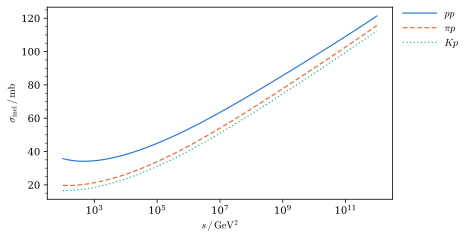

In [4]:
s = np.logspace(2, 12, 300)
ref = sigma(13e3**2, "p")  # value at the collider energy used below

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(s, sigma(s, "p"), color=blue, label="$pp$")
ax.plot(s, sigma(s, "pi"), color=orange, ls=dash, label=r"$\pi p$")
ax.plot(s, sigma(s, "K"), color=aqua, ls=dot, label="$Kp$")
ax.set(xscale="log", xlabel=r"$s \,/\, \mathrm{GeV}^2$", ylabel=r"$\sigma_\mathrm{inel} \,/\, \mathrm{mb}$")
fig.legend(loc="outside right upper")
plt.show()

The inelastic proton cross section at the collision energy $\sqrt{s} = 13 \, \mathrm{TeV}$ of the charm measurement below amounts to $\sigma_\mathrm{inel} = 76.8 \, \mathrm{mb}$ while the meson cross sections stay well below it at all energies.

## Charm Production

Charm quarks carry the energy fraction $x_c$ of an incident proton with energy $E_p$ and are produced with the differential cross section of [Gonçalves 2007](https://doi.org/10.1088/1126-6708/2007/04/028) written as

$$\frac{d\sigma}{dx_c} = \frac{a}{\tilde{A}} \, x_c^{\,b-1} \left( 1 - x_c^{\,m} \right)^{n}$$

where the coefficients $a$ and $b$ and $n$ depend linearly on the logarithm of $E_p$ while the divisor $\tilde{A}$ converts from air nuclei to single nucleons. Fragmentation into a hadron that keeps the fraction $z$ of the quark energy is described by the function $D_h$ of [Kniehl 2006](https://doi.org/10.1103/PhysRevD.74.037502) given by

$$D_h = \frac{N_h \, z \left( 1 - z \right)^2}{\left( \left( 1 - z \right)^2 + \epsilon_h z \right)^2}$$

which enters the hadron cross section at the energy fraction $x_h$ through the convolution

$$\frac{d\sigma}{dx_h} = \sqrt{1 - \frac{m_h}{x_h E_p}} \int_{x_h}^{1} \frac{dz}{z} \, \frac{d\sigma}{dx_c} \, D_h$$

with the quark fraction inside the integral fixed by the ratio of $x_h$ and $z$ and with a threshold factor for the hadron mass $m_h$ in front. The integral over $z$ is evaluated with Gauss Legendre nodes, which replaces the scalar loop of the original code.

In [5]:
def quark(x, E, A):
    """charm quark cross section per energy fraction in mb"""
    L = np.log(E)
    a, b, n = 0.403 * L - 2.002, 0.237 - 0.023 * L, 7.639 - 0.102 * L
    return a * x ** (b - 1) * (1 - x**1.2) ** n / A


def frag(z, h):
    """charm quark to hadron fragmentation function"""
    N, eps = had[h]["N"], had[h]["eps"]
    return N * z * (1 - z) ** 2 / ((1 - z) ** 2 + eps * z) ** 2


def cut(x, E, h):
    """threshold factor for the hadron mass"""
    return np.sqrt(np.clip(1 - had[h]["m"] / (x * E), 0, None))


u, wu = np.polynomial.legendre.leggauss(32)
u, wu = (u + 1) / 2, wu / 2  # nodes and weights on the unit interval


def hadron(x, E, h, A):
    """charmed hadron cross section per energy fraction in mb"""
    x, E = np.broadcast_arrays(np.minimum(x, 1.0), E)
    z = x[..., None] + (1 - x[..., None]) * u  # nodes between x and one
    y = quark(x[..., None] / z, E[..., None], A) * frag(z, h) / z
    return (y @ wu) * (1 - x) * cut(x, E, h)

The thesis fixes the divisor $\tilde{A}$ by matching the integral over all $x_h$ to the charm meson cross sections of [Aaij 2016](https://doi.org/10.1007/JHEP03%282016%29159) although these only cover a forward rapidity window. A hadron with rapidity $y$ in the collision frame and negligible transverse momentum carries the energy fraction

$$x_h = \frac{m_h}{\sqrt{s}} \, e^{y}$$

which turns the rapidity limits of the measurement into limits on $x_h$ for a fair comparison. The test below repeats the thesis comparison, then restricts the integral to the measured window, where the plain nucleon number $A$ already reproduces the data.

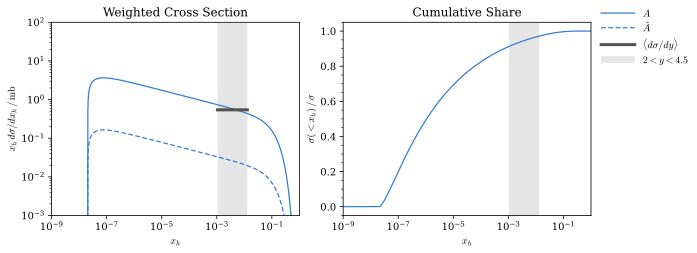

In [6]:
rs = 13e3  # collision energy of the measurement
Ep = (rs**2 - 2 * mp**2) / (2 * mp)  # same collision for a proton at rest
x = np.logspace(-10, 0, 4000)
used = {"D0": 2.072, "D+": 0.834, "Ds": 0.353}  # measured mb with a lower cut on transverse momentum
full = {"D0": 2.709, "D+": 1.102}  # measured mb for all transverse momenta

r = [2 * np.trapezoid(hadron(x, Ep, h, 14.5), x) / v for h, v in used.items()]  # both charges
q = []
for h, v in full.items():
    xw = had[h]["m"] / rs * np.exp(np.linspace(2.0, 4.5, 400))  # rapidity window
    q.append(2 * np.trapezoid(hadron(xw, Ep, h, 14.5), xw) / v)

y = hadron(x, Ep, "D0", 14.5)
x0 = had["D0"]["m"] / rs * np.exp([2.0, 4.5])  # window limits for neutral mesons
share = np.cumsum(y * np.gradient(x)) / np.sum(y * np.gradient(x))

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
axes[0].plot(x, x * y, color=blue, label="$A$")
axes[0].plot(x, x * y * 14.5 / 323.64, color=blue, ls=dash, label=r"$\tilde{A}$")
axes[0].plot(x0, [full["D0"] / 5] * 2, color=ink, lw=3, label=r"$\langle d\sigma / dy \rangle$")  # mean per rapidity and charge
axes[0].set(xscale="log", yscale="log", xlim=(1e-9, 1), ylim=(1e-3, 1e2), title="Weighted Cross Section")
axes[0].set(xlabel="$x_h$", ylabel=r"$x_h \, d\sigma / dx_h \,/\, \mathrm{mb}$")
axes[1].plot(x, share, color=blue)
axes[1].set(xscale="log", xlim=(1e-9, 1), title="Cumulative Share", xlabel="$x_h$", ylabel=r"$\sigma(<x_h) \,/\, \sigma$")
for ax in axes:
    ax.axvspan(*x0, color=ink, alpha=0.15, lw=0, label="$2 < y < 4.5$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside right upper")
plt.show()

Integrated over all energy fractions the parametrization with $A$ exceeds the measured cross sections by the factor $22.3 \pm 2.3$ on average over the three mesons, which the thesis absorbs into the larger divisor $\tilde{A}$ as an overall rescaling. Restricted to the measured window the same parametrization gives $1.07 \pm 0.01$ times the data for the two mesons measured without a cut on transverse momentum, so the plain nucleon number already matches the measurement.

## Spectral Distributions

The number of hadrons per proton interaction and hadron energy $E_h$ is the distribution $F_{ph}$ which for charm follows from the cross section above as

$$F_{ph} = \frac{1}{E_p \, \sigma_{pp}} \frac{d\sigma}{dx_h}$$

with the inelastic proton cross section $\sigma_{pp}$ as normalization. Pions use the fit of [Kelner 2006](https://doi.org/10.1103/PhysRevD.74.034018) to event generator results in the form

$$F_{p\pi} = \frac{4 \alpha B}{E_p} \, x^{\alpha - 1} \left( \frac{1 - x^\alpha}{1 + r x^\alpha \left( 1 - x^\alpha \right)} \right)^4 \left( \frac{1}{1 - x^\alpha} + \frac{r \left( 1 - 2 x^\alpha \right)}{1 + r x^\alpha \left( 1 - x^\alpha \right)} \right) \sqrt{1 - \frac{m_\pi}{x E_p}}$$

where the shape parameters $B$ and $\alpha$ and $r$ vary slowly with $E_p$ and where kaons reuse the same form with their own mass and a constant relative weight.

Neutrinos with the fraction $y$ of the parent energy come from two body decays of pions and kaons with the flat distribution

$$F_{h\nu} = \frac{\mathscr{F}_h}{E_h \left( 1 - \lambda_h \right)}$$

below the kinematic limit set by the squared mass ratio $\lambda_h$ of muon and hadron, whereas charmed hadrons use the three body form of [Bhattacharya 2016](https://doi.org/10.1007/JHEP11%282016%29167) written as

$$F_{h\nu} = \frac{\mathscr{F}_h}{E_h \, \Delta_h} \left( 6 b_h a_h^2 - 4 a_h^3 - 12 \lambda_h^2 a_h + 12 \lambda_h^2 y - 6 b_h y^2 + 4 y^3 + 12 \lambda_h^2 \ln \frac{1 - y}{\lambda_h} \right)$$

where $\lambda_h$ now denotes the squared ratio of an effective hadronic mass and the parent mass, with the abbreviations

$$a_h = 1 - \lambda_h \qquad b_h = 1 - 2 \lambda_h \qquad \Delta_h = 1 - 8 \lambda_h - 12 \lambda_h^2 \ln \lambda_h + 8 \lambda_h^3 - \lambda_h^4$$

and with the branching fraction $\mathscr{F}_h$ as overall weight. The flat distribution ends in a step, so the grid cell that contains the step is weighted by its overlap with the allowed range.

In [7]:
def meson(x, E, h):
    """pion or kaon number per interaction and hadron energy"""
    L = np.log(E / 1e3)
    C = 3.67 + 0.83 * L + 0.075 * L**2
    B, a, r = C + 0.25, 0.98 / np.sqrt(C), 2.6 / np.sqrt(C)
    v = 1 - np.minimum(x, 1.0) ** a
    w = 1 + r * (1 - v) * v
    F = 4 * a * B * x ** (a - 1) * v**3 * (1 + r * v * (2 * v - 1) / w) / w**4
    return had[h]["w"] * F * cut(x, E, h) / E


def produce(x, E, h, A):
    """hadron number per interaction and hadron energy"""
    if h in charm:
        return hadron(x, E, h, A) / (E * sigma(2 * (E * mp + mp**2), "p"))
    return meson(x, E, h)


def decay(Enu, Eh, h, smooth=True):
    """neutrino number per decay and neutrino energy"""
    p, y = had[h], Enu / Eh
    if h in charm:
        l = (p["s"] / p["m"]) ** 2
        a, b = 1 - l, 1 - 2 * l
        D = 1 - 8 * l - 12 * l**2 * np.log(l) + 8 * l**3 - l**4
        v = np.minimum(y, a)  # kinematic limit
        F = 6 * b * a**2 - 4 * a**3 - 12 * l**2 * a + 12 * l**2 * v - 6 * b * v**2 + 4 * v**3
        F = (F + 12 * l**2 * np.log((1 - v) / l)) / D * (y < a)
    else:
        a = 1 - (mmu / p["m"]) ** 2
        k = np.log(a / y) / np.log(Eh[1] / Eh[0])  # distance from the limit in grid cells
        F = (np.clip(0.5 + k, 0, 1) if smooth else k >= 0) / a
    return p["f"] * F / Eh


def weights(x, rule):
    """quadrature weights on a grid"""
    d = np.diff(x)
    if rule == "riemann":
        return np.append(0, d)
    return (np.append(d, 0) + np.append(0, d)) / 2

Each decay distribution has to integrate to its branching fraction on the discrete grid, and each fragmentation function to the measured fraction of charm quarks that end in the given hadron.

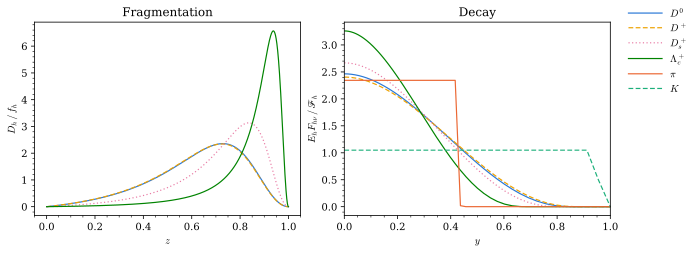

In [8]:
E = np.logspace(5, 12, 351)
w = weights(E, "trapezoid")
z = np.linspace(0, 1, 2001)
frac = dict(zip(charm, [0.606, 0.244, 0.081, 0.061]))  # measured fragmentation fractions

F = {h: decay(E[:, None], E, h)[:, 300] * E[300] / had[h]["f"] for h in had}  # one column of the decay matrix
dn = max(abs((F[h] * w).sum() / E[300] - 1) for h in had)
df = max(abs(np.trapezoid(frag(z, h), z) / frac[h] - 1) for h in charm)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
for h, col, ls, label in zip(charm, [blue, yellow, pink, green], ["-", dash, dot, "-"], ["$D^0$", "$D^+$", "$D_s^+$", r"$\Lambda_c^+$"]):
    axes[0].plot(z, frag(z, h) / frac[h], color=col, ls=ls, label=label)
    axes[1].plot(E / E[300], F[h], color=col, ls=ls)
axes[1].plot(E / E[300], F["pi"], color=orange, label=r"$\pi$")
axes[1].plot(E / E[300], F["K"], color=aqua, ls=dash, label="$K$")
axes[0].set(title="Fragmentation", xlabel="$z$", ylabel=r"$D_h \,/\, f_h$")
axes[1].set(title="Decay", xlim=(0, 1), xlabel="$y$", ylabel=r"$E_h F_{h\nu} \,/\, \mathscr{F}_h$")
fig.legend(loc="outside right upper")
plt.show()

On the grid the decay distributions integrate to their branching fractions within a relative error of $5.3 \times 10^{-4}$ and the fragmentation functions match the measured fractions within a relative error of $2.7 \times 10^{-2}$ at most.

## Attenuation

Hadrons that scatter before they decay lose their energy, which the cooling factor $\mathscr{C}$ accounts for through the ratio of the cooling time $t_\mathrm{cool}$ and the decay time $t_\mathrm{dec}$ in the form

$$\mathscr{C} = 1 - \exp \left( - \frac{t_\mathrm{cool}}{t_\mathrm{dec}} \right)$$

where both times follow from the target density $n$ and the hadron lifetime $\tau_h$ as

$$t_\mathrm{cool} = \frac{1}{\kappa_{hp} \, \sigma_{hp} \, n \, c} \qquad t_\mathrm{dec} = \frac{\tau_h E_h}{m_h}$$

with a constant inelasticity $\kappa_{hp}$ for all hadrons. Protons cross a target of size $d$ with the optical depth $\mathscr{O}$ defined as

$$\mathscr{O} = \kappa_{pp} \, \sigma_{pp} \, n \, d$$

which the thesis applies as a plain factor and which the corrected version turns into the interaction probability

$$\mathscr{P} = 1 - \exp \left( - \mathscr{O} \right)$$

that stays below unity for any target. Both functions take the conversion from millibarn to square centimetres as an argument, which is where the thesis code used the factor for barn.

In [9]:
def cooling(E, n, h, mb, d=None):
    """probability of decay before energy loss"""
    p = had[h]
    s = 2 * E * mp + mp**2 + p["m"] ** 2
    tcool = 1 / (0.8 * sigma(s, "pi" if h == "pi" else "K") * mb * n * c)
    tdec = p["tau"] * E / p["m"]
    q = tcool / tdec
    if d is not None:
        q = np.where(d < c * tdec, c * tcool / d, q)  # decay outside the target
    return -np.expm1(-q)


def depth(E, n, d, cfg):
    """proton interaction factor for a target of size d"""
    O = 0.5 * sigma(2 * (E * mp + mp**2), "p") * cfg["mb"] * n * d
    return {"none": np.ones_like(O), "linear": O, "bounded": -np.expm1(-O)}[cfg["depth"]]

## Sources

The magnetar injects protons at the single energy $E^M$ that falls with time $t$ on the spindown scale $t_\mathrm{sd}$ as

$$E^M = \frac{\eta \, e B R^3 \omega_0^2}{2 c^2} \left( 1 + \frac{t}{t_\mathrm{sd}} \right)^{-1}$$

while the injection rate follows the same decline and the ejecta expand at constant velocity, so that their radius $r$ and density $n$ read

$$r = \beta c \, t \qquad n = \frac{3 M}{4 \pi r^3 m_p}$$

for an ejecta mass $M$ made of protons. The accretion disk is a uniform slab of fixed density and height that is hit by protons with an inverse square power law spectrum up to a maximum energy. In both cases hadron and neutrino spectra follow from folding integrals such as

$$\frac{dN_\nu}{dE_\nu} = \int dE_h \, \frac{dN_h}{dE_h} \, F_{h\nu}$$

which become matrix products with quadrature weights on a logarithmic grid.

In [10]:
B, R, omega, chi, I = 10**14.5, 1e6, 1e4, 0.95, 1e45  # field, radius, rotation, tilt and inertia
eta, beta, M = 0.1, 0.1, 10  # acceleration efficiency, ejecta velocity and ejecta mass

K = (B * R**3 / 2) ** 2 * (1 + np.sin(chi) ** 2) / c**3  # force free spindown coefficient
tsd = I / (2 * K * omega**2)
E0 = eta * e * B * R**3 * omega**2 / (2 * c**2) * erg  # initial proton energy
N0 = B * R**3 * omega**2 / (e * c)  # initial proton rate


def magnetar(t, E, cfg):
    """neutrino spectra per time from a young magnetar"""
    Ep = E0 / (1 + t / tsd)
    r = beta * c * t
    n = 3 * M * sun / (4 * np.pi * r**3 * gram)
    S = N0 / (1 + t / tsd) * depth(Ep, n, r, cfg)
    w, smooth = weights(E, cfg["rule"]), cfg["rule"] == "trapezoid"
    out = {}
    for h in had:
        Sh = S * produce(E[:, None] / Ep, Ep, h, cfg["A"]) * cooling(E[:, None], n, h, cfg["mb"])
        out[h] = (decay(E[:, None], E, h, smooth) * w) @ Sh
    return out


def nucleus(Ep, E, cfg, n=1e14, d=1e15):
    """neutrino spectra from an accretion disk"""
    Sp = Ep**-2.0 * depth(Ep, n, d, cfg)
    wp, w, smooth = weights(Ep, cfg["rule"]), weights(E, cfg["rule"]), cfg["rule"] == "trapezoid"
    out = {}
    for h in had:
        Sh = (produce(E[:, None] / Ep, Ep, h, cfg["A"]) * wp) @ Sp * cooling(E, n, h, cfg["mb"], d)
        out[h] = (decay(E[:, None], E, h, smooth) * w) @ Sh
    return out


def total(nu):
    """summed charm spectrum"""
    return sum(nu[h] for h in charm)


def fluence(S, t, a, b):
    """time integral of a spectrum between two bounds"""
    m = (t > 0.999 * a) & (t < 1.001 * b)  # grid points inside the window
    return np.trapezoid(S[:, m], t[m], axis=1)

The first check of the source model compares the cooling factor at one hadron energy and the interaction probability for both unit conversions. With the corrected conversion every cooling feature moves to earlier times by one decade, and the ejecta stay opaque for protons far longer than the time span that matters at this energy.

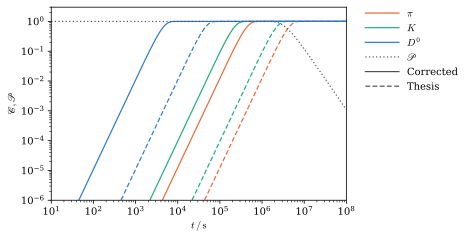

In [11]:
t = np.logspace(1, 8, 561)
r = beta * c * t
n = 3 * M * sun / (4 * np.pi * r**3 * gram)
Eh = 2e9  # hadron energy behind the reference neutrino energy
tn, to = [t[np.abs(cooling(Eh, n, "D0", cfg["mb"]) - (1 - np.exp(-1))).argmin()] for cfg in (new, old)]  # equal time scales
P = depth(E0 / (1 + t / tsd), n, r, new)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
for h, col, name in [("pi", orange, r"$\pi$"), ("K", aqua, "$K$"), ("D0", blue, "$D^0$")]:
    ax.plot(t, cooling(Eh, n, h, new["mb"]), color=col, label=name)
    ax.plot(t, cooling(Eh, n, h, old["mb"]), color=col, ls=dash)
ax.plot(t, P, color=ink, ls=dot, label=r"$\mathscr{P}$")
ax.set(xscale="log", yscale="log", xlim=(1e1, 1e8), ylim=(1e-6, 3), xlabel=r"$t \,/\, \mathrm{s}$", ylabel=r"$\mathscr{C}, \mathscr{P}$")
lines, labels = ax.get_legend_handles_labels()
lines += [Line2D([], [], color=ink), Line2D([], [], color=ink, ls=dash)]
fig.legend(lines, labels + ["Corrected", "Thesis"], loc="outside right upper")
plt.show()

The force free spindown proceeds on the time scale $t_\mathrm{sd} = 3.24 \times 10^{3} \, \mathrm{s}$ and protons start at $E^M = 5.27 \times 10^{11} \, \mathrm{GeV}$ for the field used here, which becomes $1.67 \times 10^{12} \, \mathrm{GeV}$ for the reference field of [Carpio 2020](https://doi.org/10.1103/PhysRevD.102.103001) which the thesis derives as well. At the reference hadron energy cooling and decay of $D^0$ mesons balance after $4.5 \times 10^{3} \, \mathrm{s}$ instead of $4.5 \times 10^{4} \, \mathrm{s}$ with the thesis conversion, while the ejecta stay opaque until about $4.3 \times 10^{6} \, \mathrm{s}$ when the interaction probability drops below one half.

## Reproduction

With the thesis settings the vectorized code has to return the tables stored with the thesis, which the next cell checks for both magnetar variants and for the accretion disk before anything is changed.

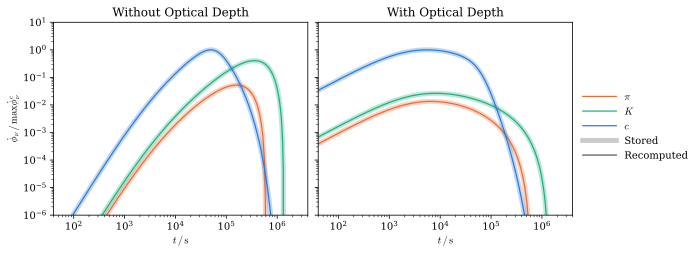

In [12]:
root = "tables"  # stored thesis tables
files = dict(zip(had, ["pi", "K", "D0", "Dplus", "DplusS", "LAMplusC"]))
t0, E0g = np.logspace(1, 8, 500), np.logspace(5, 12, 100)  # thesis grids for the magnetar
Ep0, Eh0 = np.logspace(5, 12, 200), np.logspace(5, 12, 1000)  # thesis grids for the disk
i0 = np.abs(E0g - 1e9).argmin()

thesis = {"without": magnetar(t0, E0g, old), "with": magnetar(t0, E0g, old | {"depth": "linear"})}
disk0 = nucleus(Ep0, Eh0, old | {"depth": "linear"})

dc = dm = dd = 0
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, (key, nu), title in zip(axes, thesis.items(), ["Without Optical Depth", "With Optical Depth"]):
    ref = {h: np.loadtxt(f"{root}/magnetar/{key}/{files[h]}.txt") for h in had}
    for h in had:
        m = (ref[h] > 0) & (t0 > 1e3)
        d = np.abs(nu[h][m] / ref[h][m] - 1).max()
        dc, dm = (max(dc, d), dm) if h in charm else (dc, max(dm, d))
    top = total(ref)[i0].max()
    for S, T, col in [(nu["pi"], ref["pi"], orange), (nu["K"], ref["K"], aqua), (total(nu), total(ref), blue)]:
        ax.plot(t0, T[i0] / top, color=col, lw=5, alpha=0.3)
        ax.plot(t0, S[i0] / top, color=col)
    ax.set(xscale="log", yscale="log", xlim=(4e1, 4e6), ylim=(1e-6, 1e1), title=title, xlabel=r"$t \,/\, \mathrm{s}$")
axes[0].set_ylabel(r"$\dot\phi_\nu \,/\, \max \dot\phi_\nu^c$")
lines = [Line2D([], [], color=col) for col in (orange, aqua, blue)]
lines += [Line2D([], [], color=ink, lw=5, alpha=0.3), Line2D([], [], color=ink)]
fig.legend(lines, [r"$\pi$", "$K$", "$c$", "Stored", "Recomputed"], loc="outside right center")

for h in had:
    ref = np.loadtxt(f"{root}/nucleus/{files[h]}.txt")[:, 1]
    dd = max(dd, np.abs(1e30 * disk0[h][ref > 0] / ref[ref > 0] - 1).max())

Recomputed charm spectra deviate from the stored tables by at most $10^{-6}$ relative to the stored values, which is the precision of the quadrature nodes, and the disk spectra by at most $3 \times 10^{-7}$ for all hadrons. Pions and kaons agree within $6 \times 10^{-4}$ after the first thousand seconds, and the larger differences before that sit where the stored cooling factor consists of rounding noise. Together the three thesis runs take less than one second with the vectorized code.

## Magnetar

The corrected run uses grids that contain every decade, so that the reference neutrino energy and all integration bounds fall on grid points. Each figure shows the thesis result without optical depth on the left and the corrected result on the right, both normalized to their own charm maximum and with the same uncertainty band around charm as in the thesis.

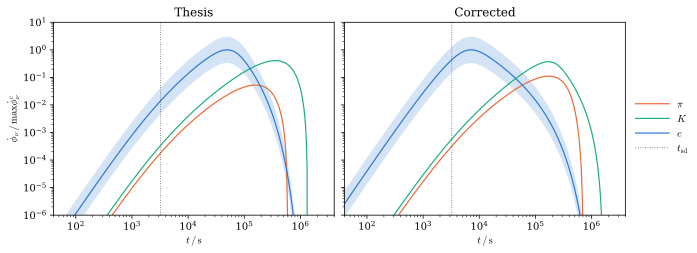

In [13]:
t, E = np.logspace(1, 8, 561), np.logspace(5, 12, 351)
i = np.abs(E - 1e9).argmin()

fixed = magnetar(t, E, new)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, tt, nu, k, title in [(axes[0], t0, thesis["without"], i0, "Thesis"), (axes[1], t, fixed, i, "Corrected")]:
    ch = total(nu)[k]
    ax.fill_between(tt, ch / 3 / ch.max(), 3 * ch / ch.max(), color=blue, alpha=0.2, lw=0)
    ax.plot(tt, nu["pi"][k] / ch.max(), color=orange, label=r"$\pi$")
    ax.plot(tt, nu["K"][k] / ch.max(), color=aqua, label="$K$")
    ax.plot(tt, ch / ch.max(), color=blue, label="$c$")
    ax.axvline(tsd, color=ink, lw=0.8, ls=dot, label=r"$t_\mathrm{sd}$")
    ax.set(xscale="log", yscale="log", xlim=(4e1, 4e6), ylim=(1e-6, 1e1), title=title, xlabel=r"$t \,/\, \mathrm{s}$")
axes[0].set_ylabel(r"$\dot\phi_\nu \,/\, \max \dot\phi_\nu^c$")
fig.legend(*ax.get_legend_handles_labels(), loc="outside right center")

tc, tk, tp = [t[S[i].argmax()] for S in (total(fixed), fixed["K"], fixed["pi"])]
hk, hp = fixed["K"][i].max() / ch.max(), fixed["pi"][i].max() / ch.max()

In the corrected light curves charm peaks after $7.1 \times 10^{3} \, \mathrm{s}$ shortly after the spindown time, while kaons and pions both peak after $1.7 \times 10^{5} \, \mathrm{s}$ at heights of $0.37$ and $0.11$ relative to the charm maximum. The corrected run on the finer grids takes less than one second as well.

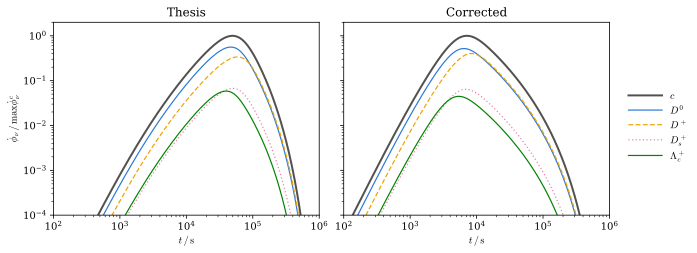

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, tt, nu, k, title in [(axes[0], t0, thesis["without"], i0, "Thesis"), (axes[1], t, fixed, i, "Corrected")]:
    ch = total(nu)[k]
    ax.plot(tt, ch / ch.max(), color=ink, lw=2, label="$c$")
    ax.plot(tt, nu["D0"][k] / ch.max(), color=blue, label="$D^0$")
    ax.plot(tt, nu["D+"][k] / ch.max(), color=yellow, ls=dash, label="$D^+$")
    ax.plot(tt, nu["Ds"][k] / ch.max(), color=pink, ls=dot, label="$D_s^+$")
    ax.plot(tt, nu["Lc"][k] / ch.max(), color=green, label=r"$\Lambda_c^+$")
    ax.set(xscale="log", yscale="log", xlim=(1e2, 1e6), ylim=(1e-4, 2e0), title=title, xlabel=r"$t \,/\, \mathrm{s}$")
axes[0].set_ylabel(r"$\dot\phi_\nu \,/\, \max \dot\phi_\nu^c$")
fig.legend(*ax.get_legend_handles_labels(), loc="outside right center")

j = ch.argmax()
shares = {h: fixed[h][i, j] / ch[j] for h in charm}  # shares at the charm maximum
peaks = {h: t[fixed[h][i].argmax()] for h in charm}

At the charm maximum the mesons $D^0$ and $D^+$ carry shares of $0.51$ and $0.38$ of the charm flux while $D_s^+$ and $\Lambda_c^+$ contribute $0.06$ and $0.04$ only. The individual peaks follow the lifetimes with $\Lambda_c^+$ first after $5.3 \times 10^{3} \, \mathrm{s}$ then $D^0$ and $D_s^+$ after $6.5 \times 10^{3} \, \mathrm{s}$ and $6.9 \times 10^{3} \, \mathrm{s}$ and finally $D^+$ after $8.4 \times 10^{3} \, \mathrm{s}$ as the longest lived charm meson.

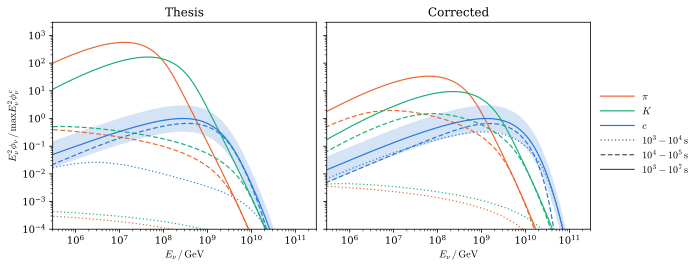

In [15]:
win = [(1e3, 1e4, dot), (1e4, 1e5, dash), (1e3, 1e7, "-")]  # integration bounds and line style
cross = []

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), sharey=True)
for ax, tt, EE, nu, title in [(axes[0], t0, E0g, thesis["without"], "Thesis"), (axes[1], t, E, fixed, "Corrected")]:
    spec = {"pi": nu["pi"], "K": nu["K"], "c": total(nu)}
    flu = {key: EE**2 * fluence(S, tt, 1e3, 1e7) for key, S in spec.items()}
    top = flu["c"].max()
    ax.fill_between(EE, flu["c"] / 3 / top, 3 * flu["c"] / top, color=blue, alpha=0.2, lw=0)
    for a, b, ls in win:
        for key, col in [("pi", orange), ("K", aqua), ("c", blue)]:
            ax.plot(EE, EE**2 * fluence(spec[key], tt, a, b) / top, color=col, ls=ls)
    ax.set(xscale="log", yscale="log", xlim=(3e5, 3e11), ylim=(1e-4, 3e3), title=title, xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
    m = (EE > 1e9) & (EE < 3e10)  # range that holds the charm takeover
    lead = flu["c"][m] / np.maximum(flu["pi"], flu["K"])[m]
    cross += [EE[m][lead > 1].min(), lead[np.abs(EE[m] - 1e10).argmin()]]
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu^c$")
lines = [Line2D([], [], color=col) for col in (orange, aqua, blue)] + [Line2D([], [], color=ink, ls=ls) for a, b, ls in win]
labels = [r"$\pi$", "$K$", "$c$", r"$10^3 - 10^4 \, \mathrm{s}$", r"$10^4 - 10^5 \, \mathrm{s}$", r"$10^3 - 10^7 \, \mathrm{s}$"]
fig.legend(lines, labels, loc="outside right center")
plt.show()

Charm exceeds both meson components above $2.1 \times 10^{9} \, \mathrm{GeV}$ in the thesis and above $2.9 \times 10^{9} \, \mathrm{GeV}$ after the corrections, but at $E_\nu = 10^{10} \, \mathrm{GeV}$ its lead over the larger meson component grows from a factor of $3.0$ to a factor of $14.5$ so that even the lower band edge clears pions and kaons there.

## Accretion Disk

The disk model has no time dependence, so the comparison reduces to the charm composition and the fluence per hadron type at the density and height stated in the thesis.

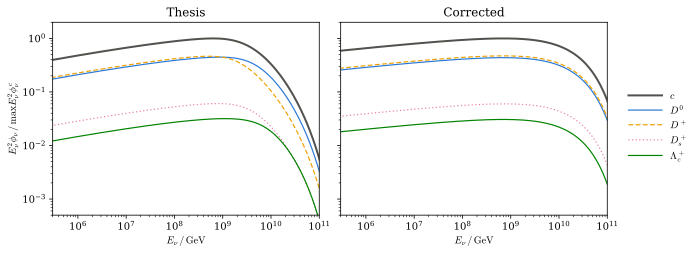

In [16]:
disk = nucleus(E, E, new)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, EE, nu, title in [(axes[0], Eh0, disk0, "Thesis"), (axes[1], E, disk, "Corrected")]:
    top = (EE**2 * total(nu)).max()
    ax.plot(EE, EE**2 * total(nu) / top, color=ink, lw=2, label="$c$")
    ax.plot(EE, EE**2 * nu["D0"] / top, color=blue, label="$D^0$")
    ax.plot(EE, EE**2 * nu["D+"] / top, color=yellow, ls=dash, label="$D^+$")
    ax.plot(EE, EE**2 * nu["Ds"] / top, color=pink, ls=dot, label="$D_s^+$")
    ax.plot(EE, EE**2 * nu["Lc"] / top, color=green, label=r"$\Lambda_c^+$")
    ax.set(xscale="log", yscale="log", xlim=(3e5, 1e11), ylim=(5e-4, 2e0), title=title, xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu^c$")
fig.legend(*ax.get_legend_handles_labels(), loc="outside right center")

r0, r1 = disk0["D+"][Eh0 < 1e11][-1] / disk0["D0"][Eh0 < 1e11][-1], disk["D+"][E < 1e11][-1] / disk["D0"][E < 1e11][-1]

At the highest plotted energy the flux from $D^+$ amounts to $0.47$ times that from $D^0$ in the thesis but to $1.13$ times after the corrections, so the cooling driven crossing of the two components now lies beyond the plotted range. The corrected disk run takes well under one second.

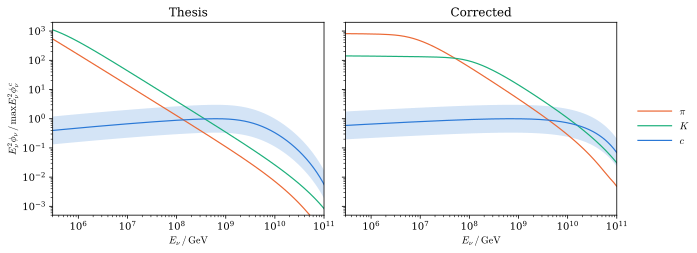

In [17]:
cross = []

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), sharey=True)
for ax, EE, nu, title in [(axes[0], Eh0, disk0, "Thesis"), (axes[1], E, disk, "Corrected")]:
    flu = {"pi": EE**2 * nu["pi"], "K": EE**2 * nu["K"], "c": EE**2 * total(nu)}
    top = flu["c"].max()
    ax.fill_between(EE, flu["c"] / 3 / top, 3 * flu["c"] / top, color=blue, alpha=0.2, lw=0)
    ax.plot(EE, flu["pi"] / top, color=orange, label=r"$\pi$")
    ax.plot(EE, flu["K"] / top, color=aqua, label="$K$")
    ax.plot(EE, flu["c"] / top, color=blue, label="$c$")
    ax.set(xscale="log", yscale="log", xlim=(3e5, 1e11), ylim=(5e-4, 2e3), title=title, xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
    m = EE < 1e11
    lead = flu["c"][m] / np.maximum(flu["pi"], flu["K"])[m]
    cross += [EE[m][lead > 1].min(), lead[-1]]
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu^c$")
fig.legend(*ax.get_legend_handles_labels(), loc="outside right center")
plt.show()

At the stated density charm overtakes pions and kaons only above $1.6 \times 10^{10} \, \mathrm{GeV}$ instead of $3.7 \times 10^{8} \, \mathrm{GeV}$ in the thesis, and at $E_\nu = 10^{11} \, \mathrm{GeV}$ it leads the larger meson component by a factor of $2.3$ instead of $6.8$ which keeps the lower band edge below the larger meson component.

The thesis already notes that the energy where charm takes over depends on the density, and the unit error is equivalent to a far denser disk. The scan below shows that energy for the corrected settings as a function of density, together with the thesis value at the stated density.

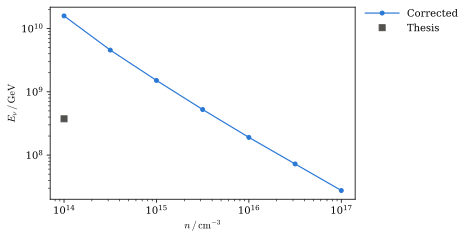

In [18]:
dens = np.logspace(14, 17, 7)
edge = []
for n in dens:
    nu = nucleus(E, E, new, n)
    edge.append(E[(total(nu) > np.maximum(nu["pi"], nu["K"])) & (E < 1e11)].min())
near = 10 ** np.interp(-np.log10(cross[0]), -np.log10(edge), np.log10(dens))  # density that returns the thesis value

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(dens, edge, color=blue, marker="o", ms=4, label="Corrected")
ax.plot(1e14, cross[0], color=ink, marker="s", ms=6, ls="none", label="Thesis")
ax.set(xscale="log", yscale="log", xlabel=r"$n \,/\, \mathrm{cm}^{-3}$", ylabel=r"$E_\nu \,/\, \mathrm{GeV}$")
fig.legend(loc="outside right upper")
plt.show()

The corrected settings recover the thesis takeover energy near a density of $4.6 \times 10^{15} \, \mathrm{cm}^{-3}$ which lies more than one decade above the density stated in the thesis.

## Convergence

Doubling both grids of the corrected magnetar run tests whether the fluence in the widest time window has converged.

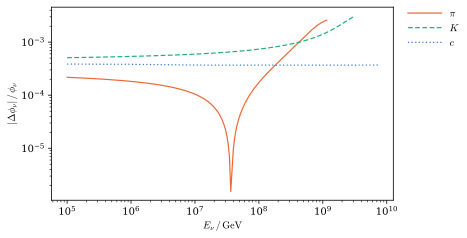

In [19]:
fine = magnetar(np.logspace(1, 8, 1121), np.logspace(5, 12, 701), new)
tf = np.logspace(1, 8, 1121)
err = {}

fig, ax = plt.subplots(figsize=(6.4, 3.2))
for key, col, ls, label in [("pi", orange, "-", r"$\pi$"), ("K", aqua, dash, "$K$"), ("c", blue, dot, "$c$")]:
    a = fluence(total(fixed) if key == "c" else fixed[key], t, 1e3, 1e7)
    b = fluence(total(fine) if key == "c" else fine[key], tf, 1e3, 1e7)[::2]
    m = (b > 1e-8 * b.max()) & (E < 1e11)
    err[key] = np.abs(a[m] / b[m] - 1)
    ax.plot(E[m], err[key], color=col, ls=ls, label=label)
ax.set(xscale="log", yscale="log", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$| \Delta \phi_\nu | \,/\, \phi_\nu$")
fig.legend(loc="outside right upper")
plt.show()

The largest relative change among pions and kaons and charm amounts to $3.1 \times 10^{-3}$ wherever the fluence is not negligible, which is far below every physical uncertainty of the model.

## Summary

- **Charm Composition**: Holds. The mesons $D^0$ and $D^+$ carry most of the charm flux while $D_s^+$ and $\Lambda_c^+$ stay at the level of a few percent, and the peaks are ordered by lifetime. For the disk the crossing between $D^+$ and $D^0$ moves above the plotted range, because charm no longer cools there.
- **Light Curves**: The order of charm first, then kaons, then pions holds. Every cooling feature moves to earlier times by about one decade, the charm peak now sits shortly after the spindown time and the three peak heights lie within one order of magnitude, which is what [Carpio 2020](https://doi.org/10.1103/PhysRevD.102.103001) describe.
- **Optical Depth**: The disagreement that the thesis traces to the optical depth disappears. The ejecta are opaque to protons throughout the relevant time span, so the bounded probability equals unity and reproduces the variant that the thesis already preferred. The remaining offset in time came from the unit conversion.
- **Charm Separation**: Changes. With the plain nucleon scaling charm exceeds pions and kaons at the highest energies even at the lower edge of its uncertainty band, so the magnetar fluence supports a separable charm component instead of leaving the question open.
- **Accretion Disk**: Changes. At the stated density pions rather than kaons dominate at low energies, charm takes over more than one decade higher in energy than in the thesis and its lower band edge no longer clears the kaons. The decline of charm at the highest energies comes from the end of the proton spectrum and not from cooling. The thesis picture returns for a disk that is more than one decade denser.
- **Proton Energy**: Holds. The initial proton energy and spindown time found above match the thesis values, and the formula of [Carpio 2020](https://doi.org/10.1103/PhysRevD.102.103001) evaluated with their reference field gives the value derived in the thesis rather than the larger one quoted there.

## References

- [Aaij 2016](https://doi.org/10.1007/JHEP03%282016%29159)
- [Belousov 2016](https://doi.org/10.1134/S1063778816010075)
- [Bhattacharya 2016](https://doi.org/10.1007/JHEP11%282016%29167)
- [Carpio 2020](https://doi.org/10.1103/PhysRevD.102.103001)
- [Fagundes 2012](https://doi.org/10.1016/j.nuclphysa.2012.01.017)
- [Gonçalves 2007](https://doi.org/10.1088/1126-6708/2007/04/028)
- [Kelner 2006](https://doi.org/10.1103/PhysRevD.74.034018)
- [Kniehl 2006](https://doi.org/10.1103/PhysRevD.74.037502)

# Extensions

The sections below extend the corrected model without changing any function above. Each extension adds one physical ingredient, and all of them share one energy grid for protons, hadrons and neutrinos so that every step remains a matrix product.

## Synchrotron Cooling

Charged hadrons and muons with mass $m$ and energy $E$ in a magnetic field $B$ radiate on the synchrotron time scale

$$t_\mathrm{syn} = \frac{6 \pi \, m^4 c^3}{\sigma_T \, m_e^2 B^2 E}$$

which follows from the radiated power of an electron scaled by the squared mass ratio, as used for nucleons and mesons in [Enberg 2009](https://doi.org/10.1103/PhysRevD.79.053006). Both loss channels add up in the cooling rate

$$\frac{1}{t_\mathrm{cool}} = \frac{1}{t_\mathrm{had}} + \frac{1}{t_\mathrm{syn}}$$

which replaces the hadronic cooling time in the cooling factor $\mathscr{C}$ of the attenuation section, while the neutral $D^0$ only cools hadronically and muons only through synchrotron radiation.

## Maximum Proton Energy

Protons gain energy on the acceleration time

$$t_\mathrm{acc} = \eta \, \frac{E_p}{e B c}$$

with a fixed multiple $\eta$ of the gyration time, and they keep gaining energy only as long as no loss channel is faster. The maximum energy $E_\mathrm{max}$ follows from the balance

$$\frac{1}{t_\mathrm{acc}} = \frac{1}{t_\mathrm{esc}} + \frac{1}{t_{pp}} + \frac{1}{t_\mathrm{syn}}$$

with the escape time $t_\mathrm{esc}$ of the source and the proton loss time $t_{pp}$ built from the same inelasticity and cross section as the optical depth, and the injected spectrum takes the form

$$\frac{dN_p}{dE_p} \propto E_p^{-2} \left( 1 + \frac{E_p}{E_\mathrm{max}} \right) \exp \left( - \frac{E_p}{E_\mathrm{max}} \right)$$

with the acceleration multiple and cutoff shape of [Enberg 2009](https://doi.org/10.1103/PhysRevD.79.053006). Photomeson losses enter the same balance in a later section.

## Muons & Flavors

Pions and kaons decay into a muon that carries an energy fraction between the squared mass ratio $r_h$ of muon and hadron and unity with the flat distribution

$$F_{h\mu} = \frac{\mathscr{F}_h}{E_h \left( 1 - r_h \right)}$$

and the muon itself decays into one electron neutrino and one muon neutrino with the energy fraction $y$ distributed for unpolarized relativistic muons as

$$F_{\mu\nu_\mu} = \frac{1}{E_\mu} \left( \frac{5}{3} - 3 y^2 + \frac{4}{3} y^3 \right) \qquad F_{\mu\nu_e} = \frac{1}{E_\mu} \left( 2 - 6 y^2 + 4 y^3 \right)$$

following [Lipari 2007](https://doi.org/10.1103/PhysRevD.75.123005) with the muon polarization neglected. Semileptonic charm decays give electron and muon neutrinos in equal numbers, and tau neutrinos are absent at the source. Averaged oscillations over cosmic distances turn the source flavors into the flavors at Earth through

$$P_{\alpha\beta} = \sum_i \left| U_{\alpha i} \right|^2 \left| U_{\beta i} \right|^2$$

with the mixing matrix $U$ built from the best fit angles and phase of [Esteban 2024](https://doi.org/10.1007/JHEP12%282024%29216) for normal ordering. The electron neutrino fraction at Earth then separates a full pion chain from a muon damped source as pointed out by [Kashti 2005](https://doi.org/10.1103/PhysRevLett.95.181101) and charm adds a third composition with equal electron and muon neutrinos.

In [20]:
me, sT, kB, hc = 0.511e-3, 6.652e-25, 8.617e-14, 1.9733e-14  # electron mass, thomson cross section, boltzmann constant and hbar c
mu = dict(m=0.1057, tau=2.197e-6)  # muon mass and lifetime
neutral = ["D0"]


def syn(E, m, B):
    """synchrotron loss rate in 1/s"""
    return erg * sT * c * B**2 * E / (6 * np.pi * (m / me) ** 2 * m**2)


def survive(E, h, n, B):
    """probability of decay before hadronic or synchrotron loss"""
    p = mu if h == "mu" else had[h]
    rate = np.zeros(np.broadcast(E, n, B).shape)
    if h != "mu":
        rate = rate + 0.8 * sigma(2 * E * mp + mp**2 + p["m"] ** 2, "pi" if h == "pi" else "K") * 1e-27 * n * c
    if h not in neutral:
        rate = rate + syn(E, p["m"], B)
    q = 1 / np.maximum(rate * p["tau"] * E / p["m"], 1e-300)  # cooling time over decay time
    return -np.expm1(-q)


Ep = np.logspace(3, 13, 501)[:, None]  # trial proton energies


def emax(n, B, tesc, loss=0.0):
    """proton energy where acceleration meets all losses"""
    acc = erg * e * B * c / (10 * Ep)  # ten gyration times
    lose = 1 / tesc + 0.5 * sigma(2 * (Ep * mp + mp**2), "p") * 1e-27 * n * c + syn(Ep, mp, B) + loss
    i = np.where(acc > lose, np.arange(len(Ep))[:, None], 0).max(0)  # last energy that still gains
    return Ep[i, 0]


def inject(E, Emax):
    """cutoff power law proton spectrum"""
    x = E / Emax
    return E**-2.0 * (1 + x) * np.exp(-np.minimum(x, 700))


def muon(Emu, Eh, h):
    """muon number per meson decay and muon energy"""
    r = (mu["m"] / had[h]["m"]) ** 2
    y, k = Emu / Eh, np.log(Eh[1] / Eh[0])
    edge = np.clip(0.5 + np.log(1 / y) / k, 0, 1) * np.clip(0.5 + np.log(y / r) / k, 0, 1)  # weighted edge cells
    return had[h]["f"] * edge / ((1 - r) * Eh)


def lepton(Enu, Emu, flavor):
    """neutrino number per muon decay and neutrino energy"""
    y = np.minimum(Enu / Emu, 1.0)
    F = 2 - 6 * y**2 + 4 * y**3 if flavor == "e" else 5 / 3 - 3 * y**2 + 4 / 3 * y**3
    return F / Emu


def rot(i, j, th, d=0.0):
    """rotation between two flavors with a phase"""
    R = np.eye(3, dtype=complex)
    R[i, i] = R[j, j] = np.cos(th)
    R[i, j], R[j, i] = np.sin(th) * np.exp(-1j * d), -np.sin(th) * np.exp(1j * d)
    return R


t12, t23, t13 = np.arcsin(np.sqrt([0.308, 0.470, 0.02215]))  # mixing angles for normal ordering
U = rot(1, 2, t23) @ rot(0, 2, t13, np.radians(212)) @ rot(0, 1, t12)
osc = np.abs(U) ** 2 @ (np.abs(U) ** 2).T  # averaged transition probabilities

A small helper builds every matrix once for a given energy grid, and one function turns proton interaction spectra into neutrino spectra per parent and flavor for any number of zones at once.

In [21]:
def kit(E):
    """production, decay and muon matrices on an energy grid"""
    w = weights(E, "trapezoid")
    return dict(
        E=E,
        P={h: produce(E[:, None] / E, E, h, new["A"]) * w for h in had},
        D={h: decay(E[:, None], E, h) * w for h in had},
        M={h: muon(E[:, None], E, h) * w for h in ["pi", "K"]},
        L={f: lepton(E[:, None], E, f) * w for f in ["e", "mu"]},
    )


Eg = np.logspace(5, 12, 351)  # common grid for protons, hadrons and neutrinos
wg = weights(Eg, "trapezoid")
main = kit(Eg)


def zone(Spp, n, B, Spg=None, k=main):
    """neutrino spectra per parent and flavor from interacting protons"""
    E = k["E"]
    Sh = {h: k["P"][h] @ Spp for h in had}
    if Spg is not None:
        shift = [np.interp(np.log(E / 0.2), np.log(E), s, right=0) for s in Spg.T]
        Sh["pg"] = np.stack(shift, 1) * 25  # each charged pion carries a fifth of the proton energy
    nu = {"c": {"e": 0, "mu": 0}}
    for key, S in Sh.items():
        h = "pi" if key == "pg" else key
        S = S * survive(E[:, None], h, n, B)
        direct = k["D"][h] @ S
        if h in charm:
            nu["c"] = {f: nu["c"][f] + direct for f in ["e", "mu"]}
        else:
            M = (k["M"][h] @ S) * survive(E[:, None], "mu", n, B)
            nu[key] = {"e": k["L"]["e"] @ M, "mu": direct + k["L"]["mu"] @ M}
    return nu


def earth(nu):
    """electron neutrino fraction at earth"""
    e = sum(v["e"] for v in nu.values())
    m = sum(v["mu"] for v in nu.values())
    return (osc[0, 0] * e + osc[0, 1] * m) / np.maximum(e + m, 1e-300)


def both(v):
    """sum over source flavors"""
    return v["e"] + v["mu"]

The first test applies the new machinery to the homogeneous disk of the thesis with the injection spectrum of the thesis, so that only the magnetic field changes between the runs. Dashed spectra belong to the run without a field and solid spectra to the intermediate field. Without a field the charm spectrum has to match the corrected disk run above.

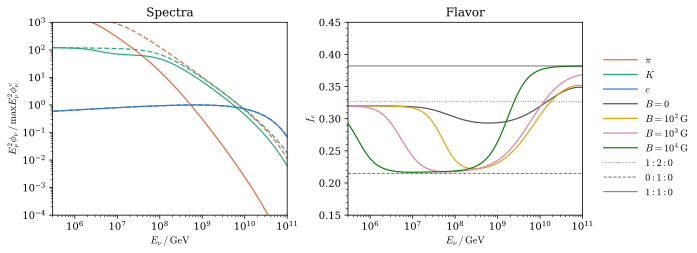

In [22]:
nd, dd = 1e14, 1e15  # thesis density and height
Sp = (Eg**-2.0 * depth(Eg, nd, dd, new))[:, None]
fields = [0.0, 1e2, 1e3, 1e4]
runs = [zone(Sp, nd, b) for b in fields]
check = total(nucleus(Eg, Eg, new))
m = check > 1e-12 * check.max()
dev = np.abs(runs[0]["c"]["mu"][m, 0] / check[m] - 1).max()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
top = (Eg**2 * both(runs[0]["c"])[:, 0]).max()
for nu, ls in [(runs[0], dash), (runs[2], "-")]:
    for key, col in [("pi", orange), ("K", aqua), ("c", blue)]:
        axes[0].plot(Eg, Eg**2 * both(nu[key])[:, 0] / top, color=col, ls=ls)
axes[0].set(xscale="log", yscale="log", xlim=(3e5, 1e11), ylim=(1e-4, 1e3), title="Spectra", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu^c$")
names = ["$B = 0$", r"$B = 10^2 \, \mathrm{G}$", r"$B = 10^3 \, \mathrm{G}$", r"$B = 10^4 \, \mathrm{G}$"]
for nu, name, col in zip(runs, names, [ink, yellow, pink, green]):
    axes[1].plot(Eg, earth(nu)[:, 0], color=col, label=name)
for src, ls in [((1, 2), dot), ((0, 1), dash), ((1, 1), "-")]:
    axes[1].axhline((osc[0, 0] * src[0] + osc[0, 1] * src[1]) / sum(src), color=ink, lw=0.8, ls=ls)
axes[1].set(xscale="log", xlim=(3e5, 1e11), ylim=(0.15, 0.45), title="Flavor", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$f_e$")
lines = [Line2D([], [], color=col) for col in (orange, aqua, blue)] + axes[1].get_lines()[:4]
lines += [Line2D([], [], color=ink, lw=0.8, ls=ls) for ls in (dot, dash, "-")]
labels = [r"$\pi$", "$K$", "$c$"] + names + [r"$1 : 2 : 0$", r"$0 : 1 : 0$", r"$1 : 1 : 0$"]
fig.legend(lines, labels, loc="outside right center")
plt.show()

Without a field the new charm spectrum reproduces the corrected disk run exactly, which confirms that the common grid and the zone function agree with the code above. A field of $10^3 \, \mathrm{G}$ suppresses pion neutrinos above about $10^7 \, \mathrm{GeV}$ through synchrotron losses while charm stays untouched, so that charm overtakes the mesons at $6.3 \times 10^{9} \, \mathrm{GeV}$ instead of $9.5 \times 10^{9} \, \mathrm{GeV}$ and already at $1.7 \times 10^{9} \, \mathrm{GeV}$ for the strongest field. The electron neutrino fraction at Earth starts at the full pion chain value $0.33$ and drops to the muon damped value $0.22$ once muons cool, which happens at lower energies for stronger fields, before charm lifts it towards the charm value $0.38$ at the highest energies.

The second test asks how far protons can be accelerated inside such a slab, using the escape time of light across its height.

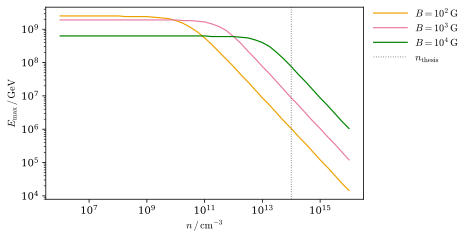

In [23]:
dens = np.logspace(6, 16, 41)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for b, col, name in [(1e2, yellow, r"$B = 10^2 \, \mathrm{G}$"), (1e3, pink, r"$B = 10^3 \, \mathrm{G}$"), (1e4, green, r"$B = 10^4 \, \mathrm{G}$")]:
    ax.plot(dens, emax(dens, b, dd / c), color=col, label=name)
ax.axvline(nd, color=ink, lw=0.8, ls=dot, label=r"$n_\mathrm{thesis}$")
ax.set(xscale="log", yscale="log", xlabel=r"$n \,/\, \mathrm{cm}^{-3}$", ylabel=r"$E_\mathrm{max} \,/\, \mathrm{GeV}$")
fig.legend(loc="outside right upper")
plt.show()

At the thesis density proton losses limit the maximum energy to values between $10^{6}$ and $10^{8} \, \mathrm{GeV}$ for these fields, far below the end of the injection spectrum assumed so far. Only for densities well below $10^{12} \, \mathrm{cm}^{-3}$ do escape and synchrotron losses take over and let the maximum energy reach about $10^{9} \, \mathrm{GeV}$ so that protons for a dense disk have to be accelerated elsewhere, which motivates the corona further below.

## Radially Resolved Disk

A standard thin disk around a black hole of mass $M$ with accretion rate $\dot{M}$ and viscosity parameter $\alpha$ provides the radial structure, following [Shakura 1973](https://ui.adsabs.harvard.edu/abs/1973A&A....24..337S) in the one zone form of [Armitage 2022](https://arxiv.org/abs/2201.07262). Angular momentum transport fixes the product of viscosity $\nu$ and surface density $\Sigma$ as

$$\nu \Sigma = \frac{\dot{M}}{3 \pi} \left( 1 - \sqrt{\frac{r_\mathrm{in}}{r}} \right)$$

with the inner edge $r_\mathrm{in}$ and the Keplerian frequency $\Omega$ that sets the scale height $h = c_s / \Omega$ through the sound speed $c_s$ and the viscosity $\nu = \alpha c_s h$ while the midplane temperature $T_c$ follows from radiative diffusion as

$$T_c^4 = \frac{9 \dot{M} \Omega^2}{32 \pi \sigma_\mathrm{SB}} \left( 1 - \sqrt{\frac{r_\mathrm{in}}{r}} \right) \tau$$

with the optical depth $\tau = \kappa \Sigma / 2$ for electron scattering. In the middle region gas pressure dominates, so that the sound speed obeys $c_s^2 = k_B T_c / \mu m_p$ and the four relations close into

$$T_c^5 = \frac{3 \kappa \mu m_p \dot{M}^2 \Omega^3}{64 \pi^2 \sigma_\mathrm{SB} \, \alpha k_B} \left( 1 - \sqrt{\frac{r_\mathrm{in}}{r}} \right)^2$$

which yields the surface density and scale height, and the midplane density follows from a Gaussian vertical profile as

$$n_0 = \frac{\Sigma}{\sqrt{2 \pi} \, h \, m_p}$$

for a hydrogen disk. The region is limited to radii where gas pressure exceeds radiation pressure and where the midplane stays hot enough to keep hydrogen ionized, while the radiation dominated inner region is left out.

## Vertical Disk Profile

Each annulus is isothermal in height $z$ with the density profile

$$n = n_0 \exp \left( - \frac{z^2}{2 h^2} \right)$$

so that protons arriving from above meet the column density

$$N = n_0 h \sqrt{\frac{\pi}{2}} \, \mathrm{erfc} \left( \frac{z}{\sqrt{2} \, h} \right)$$

down to the height $z$ and interact within a layer with the difference of $e^{-\kappa_{pp} \sigma_{pp} N}$ between its edges. Hadrons cool with the local density and with the local field from a fixed plasma beta $\beta$ given by

$$B = \sqrt{\frac{8 \pi n k_B T_c}{\beta}}$$

and each annulus receives protons in proportion to its dissipated power. The injection spectrum of the thesis is kept, so that the comparison isolates the effect of structure.

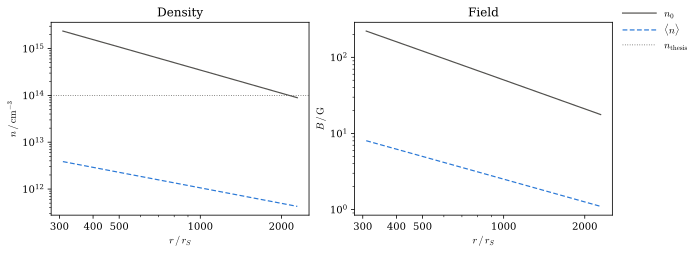

In [24]:
from math import erfc
from matplotlib.ticker import FuncFormatter

G, aR, sSB = 6.674e-8, 7.566e-15, 5.670e-5  # gravity, radiation constant and stefan boltzmann constant
kb = kB / erg  # boltzmann constant in erg per kelvin
Mbh, al, kap, mug, beta_d = 1e8 * sun, 0.1, 0.34, 0.6, 10.0  # black hole mass, viscosity, opacity, molecular weight and plasma beta
Mdot = 0.1 * 1.26e38 * 1e8 / (0.1 * c**2)  # tenth of the eddington luminosity at ten percent efficiency
RS = 2 * G * Mbh / c**2


def disk(r):
    """midplane temperature, density and scale height of the middle region"""
    J = 1 - np.sqrt(3 * RS / r)
    Om = np.sqrt(G * Mbh / r**3)
    T = (3 * kap * mug * gram * Mdot**2 * J**2 * Om**3 / (64 * np.pi**2 * sSB * al * kb)) ** 0.2
    cs2 = kb * T / (mug * gram)
    Sig = Mdot * J * Om / (3 * np.pi * al * cs2)
    h = np.sqrt(cs2) / Om
    return T, Sig / (np.sqrt(2 * np.pi) * h * gram), h


rr = RS * np.logspace(1, 5, 401)
Tr, nr, hr = disk(rr)
ok = (aR * Tr**4 / 3 < nr * kb * Tr / mug) & (Tr > 1e4)  # gas pressure dominates and hydrogen stays ionized
r = np.geomspace(rr[ok].min(), rr[ok].max(), 20)
T0, n0, h0 = disk(r)
wr = (1 - np.sqrt(3 * RS / r)) / r  # dissipated power per logarithmic radius
wr = wr / wr.sum()
B0 = np.sqrt(8 * np.pi * n0 * kb * T0 / beta_d)

zs = np.linspace(8, 0, 161)  # layer edges in scale heights from the surface to the midplane
zm = (zs[1:] + zs[:-1]) / 2
above = np.sqrt(np.pi / 2) * np.vectorize(erfc)(zs / np.sqrt(2))  # column above each edge in units of the midplane column
kp = 0.5 * sigma(2 * (Eg * mp + mp**2), "p") * 1e-27  # inelasticity times cross section

surv = np.exp(-kp[:, None, None] * (n0 * h0)[None, :, None] * above[None, None, :])
dP = surv[:, :, :-1] - surv[:, :, 1:]  # interaction probability per layer
nz = n0[:, None] * np.exp(-zm**2 / 2)
Bz = np.sqrt(8 * np.pi * nz * kb * T0[:, None] / beta_d)

Spr = inject(Eg, np.inf)[:, None] * wr * -np.expm1(-kp[:, None] * n0 * h0 * np.sqrt(2 * np.pi))
annuli = zone(Spr, n0, B0)
Spz = (inject(Eg, np.inf)[:, None, None] * wr[None, :, None] * dP).reshape(len(Eg), -1)
layers = zone(Spz, nz.ravel(), Bz.ravel())
k9 = np.abs(Eg - 1e9).argmin()
nint = (dP[k9] * nz).sum(1) / dP[k9].sum(1)  # mean density where protons of this energy interact
Bint = (dP[k9] * Bz).sum(1) / dP[k9].sum(1)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
axes[0].plot(r / RS, n0, color=ink, label="$n_0$")
axes[0].plot(r / RS, nint, color=blue, ls=dash, label=r"$\langle n \rangle$")
axes[0].axhline(nd, color=ink, lw=0.8, ls=dot, label=r"$n_\mathrm{thesis}$")
axes[0].set(xscale="log", yscale="log", title="Density", xlabel=r"$r \,/\, r_S$", ylabel=r"$n \,/\, \mathrm{cm}^{-3}$")
axes[1].plot(r / RS, B0, color=ink)
axes[1].plot(r / RS, Bint, color=blue, ls=dash)
axes[1].set(xscale="log", yscale="log", title="Field", xlabel=r"$r \,/\, r_S$", ylabel=r"$B \,/\, \mathrm{G}$")
for ax in axes:
    ax.set_xticks([300, 400, 500, 1000, 2000], ["300", "400", "500", "1000", "2000"])  # plain labels as major ticks
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
fig.legend(loc="outside right upper")
plt.show()

Protons of all energies interact in the upper layers, where the mean density stays orders of magnitude below the midplane value and the field drops accordingly. The next figure compares the homogeneous slab of the thesis with the annuli at their midplane density and with the full vertical profile.

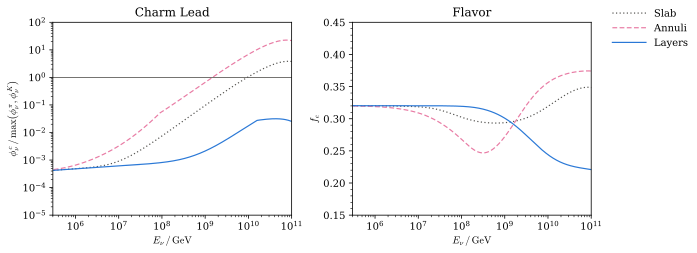

In [25]:
models = {"Slab": (runs[0], ink, dot), "Annuli": (annuli, pink, dash), "Layers": (layers, blue, "-")}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
for name, (nu, col, ls) in models.items():
    flat = {k: {f: v[f].sum(1) for f in v} for k, v in nu.items()}
    lead = both(flat["c"]) / np.maximum(np.maximum(both(flat["pi"]), both(flat["K"])), 1e-300)
    axes[0].plot(Eg, lead, color=col, ls=ls, label=name)
    axes[1].plot(Eg, earth(flat), color=col, ls=ls)
axes[0].axhline(1, color=ink, lw=0.8)
axes[0].set(xscale="log", yscale="log", xlim=(3e5, 1e11), ylim=(1e-5, 1e2), title="Charm Lead", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$\phi_\nu^c \,/\, \max \left( \phi_\nu^\pi, \phi_\nu^K \right)$")
axes[1].set(xscale="log", xlim=(3e5, 1e11), ylim=(0.15, 0.45), title="Flavor", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$f_e$")
fig.legend(loc="outside right upper")
plt.show()

The thin disk of a black hole with $M = 10^8 \, M_\odot$ at a tenth of the Eddington luminosity has a middle region between about $310$ and $2300$ Schwarzschild radii with midplane densities from $9 \times 10^{13}$ to $2 \times 10^{15} \, \mathrm{cm}^{-3}$ which brackets the thesis value. Treating each annulus as a homogeneous slab at its midplane density moves the charm takeover down to $1.5 \times 10^{9} \, \mathrm{GeV}$ because the inner annuli are denser than the thesis slab. The vertical profile reverses this picture, since protons interact where the density is only $4 \times 10^{11}$ to $4 \times 10^{12} \, \mathrm{cm}^{-3}$ and the field only a few gauss, so mesons barely cool and charm stays at a few percent of the meson flux at most. The same weak field still lets muons cool above roughly $10^{9} \, \mathrm{GeV}$ which drives the electron neutrino fraction towards the muon damped value instead of the charm value.

## Photomeson Interactions

Protons with Lorentz factor $\gamma$ in an isotropic photon field with density $n_\gamma$ per photon energy $\varepsilon$ lose energy at the rate

$$t_{p\gamma}^{-1} = \frac{c}{2 \gamma^2} \int d\varepsilon' \, \sigma_{p\gamma} \, \kappa_{p\gamma} \, \varepsilon' \int_{\varepsilon' / 2 \gamma}^{\infty} d\varepsilon \, \frac{n_\gamma}{\varepsilon^2}$$

where $\varepsilon'$ denotes the photon energy in the proton rest frame. The cross section follows the delta approximation of [Mücke 1999](https://doi.org/10.1071/AS99160) as a step of constant height across the width of the resonance with inelasticity $\kappa_{p\gamma}$ of one fifth and one charged pion in a third of the interactions, extended by a constant multipion plateau at the level of the measured high energy cross section with the larger inelasticity that the same work finds once multipion production dominates. Each charged pion carries one fifth of the proton energy, so that a share $\varphi$ of the lost energy ends in charged pions and the pion spectrum follows from the proton spectrum at five times the pion energy. Protons that stay in a source for the time $t_\mathrm{esc}$ split between both channels with the efficiencies

$$f_{pp} = \frac{t_\mathrm{esc}}{t_{pp}} \qquad f_{p\gamma} = \frac{t_\mathrm{esc}}{t_{p\gamma}}$$

and the bounded probability $1 - e^{-f_{pp} - f_{p\gamma}}$ is shared in proportion to the two efficiencies. Charm production in photon collisions and kaons from photomeson interactions are neglected.

In [26]:
eps = np.logspace(-12, -2, 401)  # photon energies in GeV
dl = np.log(eps[1] / eps[0])
mD, wD = 1.232, 0.115  # delta mass and width
er = np.geomspace(((mD - wD / 2) ** 2 - mp**2) / (2 * mp), 1e9, 257)  # photon energies in the proton rest frame
res = er < ((mD + wD / 2) ** 2 - mp**2) / (2 * mp)
xs, inel, npi = np.where(res, 5e-28, 1.2e-28), np.where(res, 0.2, 0.6), np.where(res, 1 / 3, 2.0)  # cross section, inelasticity and charged pions
wer = weights(er, "trapezoid")


def planck(T):
    """blackbody photon density per energy"""
    x = eps[:, None] / (kB * np.atleast_1d(T))
    return eps[:, None] ** 2 / (np.pi**2 * hc**3) / np.expm1(np.minimum(x, 700))


def photomeson(E, dn):
    """photomeson loss rate in 1/s and charged pion share of the lost energy"""
    g = (E / mp)[:, None]
    tail = np.cumsum((dn / eps[:, None])[::-1], 0)[::-1] * dl  # photons per squared energy above each energy
    p = np.clip(np.log(er / (2 * g) / eps[0]) / dl, 0, len(eps) - 1.001)  # position of the lower limit on the grid
    i, fr = p.astype(int), (p % 1)[..., None]
    G = tail[i] * (1 - fr) + tail[i + 1] * fr
    base = (c / (2 * g**2) * xs * er * wer)[..., None] * G
    loss = (base * inel[None, :, None]).sum(1)
    return loss, 0.2 * (base * npi[None, :, None]).sum(1) / np.maximum(loss, 1e-300)


def split(S, fpp, fpg, phi):
    """proton spectra for both channels from their efficiencies"""
    P = -np.expm1(-fpp - fpg) / np.maximum(fpp + fpg, 1e-300)
    return S * P * fpp, S * P * fpg * phi

## Magnetized Corona

The corona follows the prescription of [Murase 2020](https://doi.org/10.1103/PhysRevLett.125.011101) for a Seyfert galaxy with an X ray luminosity of $10^{43} \, \mathrm{erg/s}$ where the black hole mass, the photon index, the electron temperature and the proton density come from the table of that work. The corona is a sphere of thirty Schwarzschild radii with the virial proton temperature

$$k_B T_p = \frac{m_p c^2}{6 \mathcal{R}}$$

for the radius $\mathcal{R}$ in Schwarzschild radii, a field from a plasma beta of unity and protons that fall in at a tenth of the Keplerian speed, which sets the escape time. Coronal X rays follow a power law with an exponential cutoff at twice the electron temperature, normalized to the luminosity between two and ten kiloelectronvolt, and disk photons follow a blackbody at the maximum disk temperature of that work above two electronvolt. Both fields fill the corona with the energy density of their luminosity spread over the area $2 \pi R^2$ moving at the speed of light. Protons are accelerated with the same ten gyration times as before, which is a simpler choice than the stochastic acceleration of the original model.

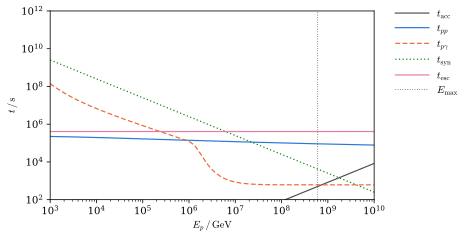

In [27]:
lx, ldisk, gx, the, ncor = 1e43, 10**44.2, 1.80, 0.23, 10**9.93  # luminosities, photon index, electron temperature and density
Mc = 10**7.25 * sun
RSc = 2 * G * Mc / c**2
Rc = 30 * RSc
Bc = np.sqrt(8 * np.pi * ncor * (mp / 180) / erg)  # plasma beta of unity at the virial temperature
tesc_c = Rc / (0.1 * np.sqrt(G * Mc / Rc))  # infall at a tenth of the keplerian speed

xray = eps**-gx * np.exp(-eps / (2 * the * me)) * (eps > 1e-7)
band = (eps > 2e-6) & (eps < 1e-5)
xray *= lx * erg / (2 * np.pi * Rc**2 * c) / np.trapezoid((eps * xray)[band], eps[band])
Mdot_c = 2 * ldisk / (0.1 * c**2)
Tdisk = 0.49 * (G * Mc * Mdot_c / (72 * np.pi * sSB * RSc**3)) ** 0.25
uv = planck(Tdisk)[:, 0]
uv *= ldisk * erg / (2 * np.pi * Rc**2 * c) / np.trapezoid(eps * uv, eps) * (eps > 2e-9)
ph_c = (xray + uv)[:, None]

lossE, _ = photomeson(Ep[:, 0], ph_c)
Emax_c = emax(ncor, Bc, tesc_c, lossE)[0]
loss_c, phi_c = photomeson(Eg, ph_c)
fpp_c = 0.5 * sigma(2 * (Eg * mp + mp**2), "p")[:, None] * 1e-27 * ncor * c * tesc_c
Spp_c, Spg_c = split(inject(Eg, Emax_c)[:, None], fpp_c, loss_c * tesc_c, phi_c)
cor = zone(Spp_c, ncor, Bc, Spg_c)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(Ep, 10 * Ep / (erg * e * Bc * c), color=ink, label=r"$t_\mathrm{acc}$")
ax.plot(Ep, 1 / (0.5 * sigma(2 * (Ep * mp + mp**2), "p") * 1e-27 * ncor * c), color=blue, label=r"$t_{pp}$")
ax.plot(Ep, 1 / np.maximum(lossE, 1e-300), color=orange, ls=dash, label=r"$t_{p\gamma}$")
ax.plot(Ep, 1 / syn(Ep, mp, Bc), color=green, ls=dot, label=r"$t_\mathrm{syn}$")
ax.axhline(tesc_c, color=pink, label=r"$t_\mathrm{esc}$")
ax.axvline(Emax_c, color=ink, lw=0.8, ls=dot, label=r"$E_\mathrm{max}$")
ax.set(xscale="log", yscale="log", xlim=(1e3, 1e10), ylim=(1e2, 1e12), xlabel=r"$E_p \,/\, \mathrm{GeV}$", ylabel=r"$t \,/\, \mathrm{s}$")
fig.legend(loc="outside right upper")
plt.show()

Photomeson losses on disk photons overtake the proton proton losses above about $10^{6} \, \mathrm{GeV}$ and the acceleration time meets them at $6.0 \times 10^{8} \, \mathrm{GeV}$ which sets the maximum energy for the fast acceleration assumed here. The next figure splits the neutrino spectrum of the corona by parent, with pions from both channels shown separately.

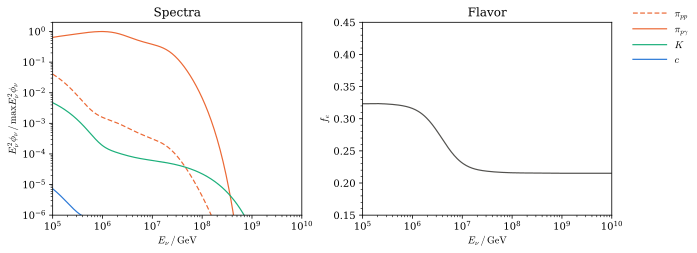

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
tot = sum(both(v)[:, 0] for v in cor.values())
top = (Eg**2 * tot).max()
for key, col, ls in [("pi", orange, dash), ("pg", orange, "-"), ("K", aqua, "-"), ("c", blue, "-")]:
    axes[0].plot(Eg, Eg**2 * both(cor[key])[:, 0] / top, color=col, ls=ls)
axes[0].set(xscale="log", yscale="log", xlim=(1e5, 1e10), ylim=(1e-6, 2), title="Spectra", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu$")
axes[1].plot(Eg, earth(cor)[:, 0], color=ink)
axes[1].set(xscale="log", xlim=(1e5, 1e10), ylim=(0.15, 0.45), title="Flavor", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$f_e$")
lines = [Line2D([], [], color=orange, ls=dash), Line2D([], [], color=orange), Line2D([], [], color=aqua), Line2D([], [], color=blue)]
fig.legend(lines, [r"$\pi_{pp}$", r"$\pi_{p\gamma}$", "$K$", "$c$"], loc="outside right upper")
plt.show()

Pions from photomeson interactions carry almost all of the neutrino energy of the corona, while charm reaches about one permille of the leading component at most because proton proton interactions lose the competition exactly at the energies where charm would matter. The field of about $1300 \, \mathrm{G}$ cools muons above roughly $10^{7} \, \mathrm{GeV}$ so that the corona is a clean example of a muon damped source with an electron neutrino fraction near $0.22$ at high energies.

## Disk Photons

Inside the disk the photon field is thermal. The effective temperature $T_\mathrm{eff}$ that radiates the dissipated power and the optical depth of electron scattering above a given height set the local temperature through the gray atmosphere relation

$$T^4 = \frac{3}{4} T_\mathrm{eff}^4 \left( \tau_T + \frac{2}{3} \right)$$

which turns into the midplane relation above once $\tau_T$ reaches half of the total optical depth. Each layer then contributes the depths $f_{pp}$ and $f_{p\gamma}$ along its thickness, and both channels share the interaction probability of the layer as in the corona.

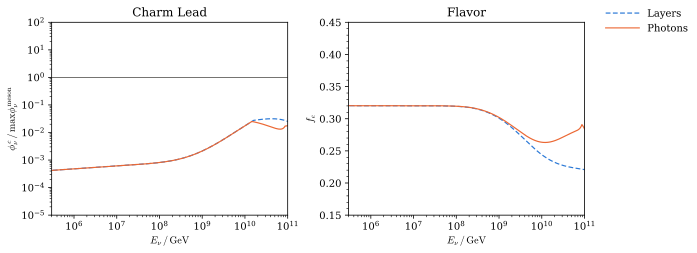

In [29]:
Teff = (3 * G * Mbh * Mdot * (1 - np.sqrt(3 * RS / r)) / (8 * np.pi * sSB * r**3)) ** 0.25
Tz = (0.75 * Teff[:, None] ** 4 * (kap * gram * (n0 * h0)[:, None] * (above[1:] + above[:-1]) / 2 + 2 / 3)) ** 0.25
Tz = np.minimum(Tz, T0[:, None])
Ttab = np.geomspace(1e3, 1e7, 81)
ltab, ptab = photomeson(Eg, planck(Ttab))
q = np.interp(np.log(Tz.ravel()), np.log(Ttab), np.arange(len(Ttab)))  # position of each layer in the temperature table
j, fr = np.minimum(q.astype(int), len(Ttab) - 2), q % 1
lz = ltab[:, j] * (1 - fr) + ltab[:, j + 1] * fr
pz = ptab[:, j] * (1 - fr) + ptab[:, j + 1] * fr

dz = (zs[0] - zs[1]) * h0[:, None].repeat(len(zm), 1).ravel()  # layer thickness
fpp_z = kp[:, None] * nz.ravel() * dz
fpg_z = lz * dz / c
edge = np.concatenate([np.zeros((len(Eg), len(r), 1)), np.cumsum((fpp_z + fpg_z).reshape(len(Eg), len(r), -1), 2)], 2)
dPz = (np.exp(-edge[..., :-1]) - np.exp(-edge[..., 1:])).reshape(len(Eg), -1)
share = 1 / np.maximum(fpp_z + fpg_z, 1e-300)
Sz = inject(Eg, np.inf)[:, None] * np.repeat(wr, len(zm))[None, :] * dPz * share
glow = zone(Sz * fpp_z, nz.ravel(), Bz.ravel(), Sz * fpg_z * pz)

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
for name, nu, col, ls in [("Layers", layers, blue, dash), ("Photons", glow, orange, "-")]:
    flat = {k: {f: v[f].sum(1) for f in v} for k, v in nu.items()}
    lead = np.maximum.reduce([both(flat[k]) for k in flat if k != "c"])
    axes[0].plot(Eg, both(flat["c"]) / np.maximum(lead, 1e-300), color=col, ls=ls, label=name)
    axes[1].plot(Eg, earth(flat), color=col, ls=ls)
axes[0].axhline(1, color=ink, lw=0.8)
axes[0].set(xscale="log", yscale="log", xlim=(3e5, 1e11), ylim=(1e-5, 1e2), title="Charm Lead", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$\phi_\nu^c \,/\, \max \phi_\nu^\mathrm{meson}$")
axes[1].set(xscale="log", xlim=(3e5, 1e11), ylim=(0.15, 0.45), title="Flavor", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$f_e$")
fig.legend(loc="outside right upper")
plt.show()

Thermal photons hardly matter in the middle region of this disk, since the effective temperature only reaches $1 \times 10^{3}$ to $5 \times 10^{3} \, \mathrm{K}$ and the layers where protons interact lie close to the photosphere. Photomeson interactions take up less than one percent of the protons even at $10^{9} \, \mathrm{GeV}$ so that the charm lead and the flavor composition stay close to the layered disk without photons.

## Magnetar Photons

The ejecta of the magnetar are opaque for a long time, so the spindown power $L$ that they absorb stays trapped as radiation and only loses energy through expansion. The radiation energy $E_\gamma$ then obeys

$$\frac{dE_\gamma}{dt} = L - \frac{E_\gamma}{t}$$

for homologous expansion, and with the spindown luminosity of the force free model the solution reads

$$E_\gamma = E_\mathrm{rot} \, \frac{t_\mathrm{sd}}{t} \left( \ln \left( 1 + \frac{t}{t_\mathrm{sd}} \right) - \frac{t}{t + t_\mathrm{sd}} \right)$$

with the rotational energy $E_\mathrm{rot}$ of the newborn star. Spread over the ejecta volume this energy defines a blackbody temperature, and protons at the injection energy cross the ejecta radius with the depths $f_{pp}$ and $f_{p\gamma}$ along that length. Pions from photomeson interactions sit at one fifth of the injection energy and cool like those from proton collisions, while the photon field is not used for inverse Compton losses of mesons. This estimate neglects photon diffusion out of the ejecta and therefore marks an upper limit for the photon density.

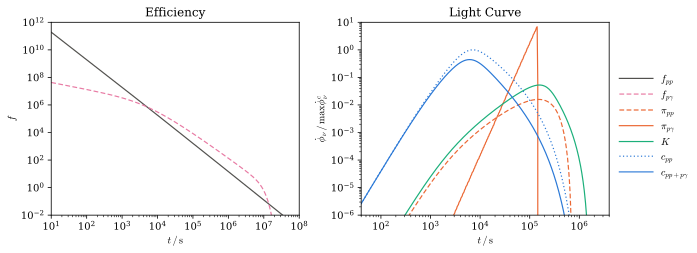

In [30]:
Erot = I * omega**2 / 2
x = t / tsd
Egam = Erot / x * (np.log1p(x) - x / (1 + x))
rad = beta * c * t
nej = 3 * M * sun / (4 * np.pi * rad**3 * gram)
Tej = (Egam / (4 * np.pi * rad**3 / 3) / aR) ** 0.25
Epm = E0 / (1 + x)
lm, phim = np.array([photomeson(np.array([a]), planck(b)) for a, b in zip(Epm, Tej)]).reshape(len(t), 2).T
fpp_m = 0.5 * sigma(2 * (Epm * mp + mp**2), "p") * 1e-27 * nej * rad
fpg_m = lm * rad / c
Ptot = -np.expm1(-fpp_m - fpg_m)
keep = Ptot * fpp_m / (fpp_m + fpg_m) / -np.expm1(-fpp_m)  # rescaling of the proton collision channel

hot = {h: fixed[h] * keep for h in had}
k = np.abs(np.log(0.2 * Epm[None, :] / Eg[:, None])).argmin(0)  # grid cell of the photomeson pions
Spi = np.zeros((len(Eg), len(t)))
Spi[k, np.arange(len(t))] = N0 / (1 + x) * Ptot * fpg_m / (fpp_m + fpg_m) * phim / 0.2 / wg[k]
hot["pg"] = main["D"]["pi"] @ (Spi * cooling(Eg[:, None], nej, "pi", new["mb"]))

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
axes[0].plot(t, fpp_m, color=ink, label=r"$f_{pp}$")
axes[0].plot(t, fpg_m, color=pink, ls=dash, label=r"$f_{p\gamma}$")
axes[0].set(xscale="log", yscale="log", xlim=(1e1, 1e8), ylim=(1e-2, 1e12), title="Efficiency", xlabel=r"$t \,/\, \mathrm{s}$", ylabel="$f$")
ch = total(fixed)[i].max()
for key, col, ls in [("pi", orange, dash), ("pg", orange, "-"), ("K", aqua, "-")]:
    axes[1].plot(t, hot[key][i] / ch, color=col, ls=ls)
axes[1].plot(t, total(fixed)[i] / ch, color=blue, ls=dot)
axes[1].plot(t, total(hot)[i] / ch, color=blue)
axes[1].set(xscale="log", yscale="log", xlim=(4e1, 4e6), ylim=(1e-6, 1e1), title="Light Curve", xlabel=r"$t \,/\, \mathrm{s}$")
axes[1].set_ylabel(r"$\dot\phi_\nu \,/\, \max \dot\phi_\nu^c$")
lines = axes[0].get_lines() + [Line2D([], [], color=orange, ls=dash), Line2D([], [], color=orange), Line2D([], [], color=aqua)]
lines += [Line2D([], [], color=blue, ls=dot), Line2D([], [], color=blue)]
labels = [r"$f_{pp}$", r"$f_{p\gamma}$", r"$\pi_{pp}$", r"$\pi_{p\gamma}$", "$K$", r"$c_{pp}$", r"$c_{pp + p\gamma}$"]
fig.legend(lines, labels, loc="outside right center")
plt.show()

Photomeson losses on the trapped radiation overtake proton collisions after $5.2 \times 10^{3} \, \mathrm{s}$ when the radiation temperature is a few hundred electronvolt, so the proton collision channel loses more than half of its protons around the charm peak and the charm peak drops to $0.44$ of its value without photons. Pions from photomeson interactions reach the reference neutrino energy only while the injection energy stays high enough, which produces a strong but short component that ends after $1.5 \times 10^{5} \, \mathrm{s}$ and dominates the fluence near $10^{9} \, \mathrm{GeV}$ while charm still leads at $10^{10} \, \mathrm{GeV}$ by a factor of $25$ over all meson components. The magnetar result therefore holds at the highest energies, with a photomeson pion bump one decade below that the thesis model could not show.

## Tidal Disruption Event

A star of mass $M_\star$ and radius $R_\star$ that passes a black hole of mass $M$ is torn apart at the tidal radius $r_t = R_\star \left( M / M_\star \right)^{1/3}$ where the debris receives a spread of specific orbital energy

$$\Delta \epsilon = \frac{G M R_\star}{r_t^2}$$

so that the most bound debris returns after the Kepler period

$$t_\mathrm{min} = \frac{2 \pi G M}{\left( 2 \Delta \epsilon \right)^{3/2}}$$

and the fallback rate decays as

$$\dot{M}_\mathrm{fb} = \frac{M_\star}{3 t_\mathrm{min}} \left( \frac{t}{t_\mathrm{min}} \right)^{-5/3}$$

following the argument of [Rees 1988](https://doi.org/10.1038/333523a0) with the exponent corrected by [Phinney 1989](https://doi.org/10.1017/S0074180900187054). The debris accretes with ten percent efficiency up to the Eddington luminosity, and a wind carries a tenth of the fallen mass outward at a tenth of the speed of light, so that its radius and density evolve like the magnetar ejecta. The wind holds a magnetic field with a tenth of its kinetic energy density, and the radiation streams through it as a diluted blackbody at the temperature of a photosphere at the wind radius. Protons are injected in proportion to the fallback rate, accelerated within the dynamical time and interact through both channels with the dynamical time as escape time.

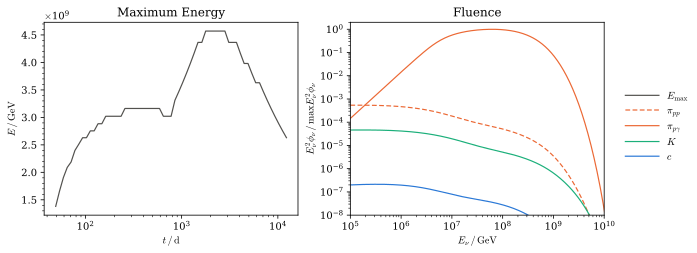

In [31]:
Mt, Rsun = 1e6 * sun, 6.957e10  # black hole mass and solar radius
rt = Rsun * (Mt / sun) ** (1 / 3)
tmin = 2 * np.pi * G * Mt / (2 * G * Mt * Rsun / rt**2) ** 1.5
tt = tmin * np.geomspace(1.2, 300, 61)
fb = sun / (3 * tmin) * (tt / tmin) ** (-5 / 3)
Lt = np.minimum(0.1 * fb * c**2, 1.26e38 * Mt / sun)
rw = 0.1 * c * tt
nw = 0.1 * sun / 2 * (1 - (tt / tmin) ** (-2 / 3)) / (4 * np.pi * rw**3 / 3 * gram)
Bw = np.sqrt(8 * np.pi * 0.1 * nw * gram * (0.1 * c) ** 2 / 2)
Tw = (Lt / (4 * np.pi * rw**2 * sSB)) ** 0.25
phw = planck(Tw) / 4  # streaming radiation carries a quarter of the blackbody energy density

Emax_w = emax(nw, Bw, tt, photomeson(Ep[:, 0], phw)[0])
loss_w, phi_w = photomeson(Eg, phw)
fpp_w = kp[:, None] * nw * c * tt
Spp_w, Spg_w = split(inject(Eg[:, None], Emax_w) * fb, fpp_w, loss_w * tt, phi_w)
tde = zone(Spp_w, nw, Bw, Spg_w)

k7 = np.abs(Eg - 1e7).argmin()
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
axes[0].plot(tt / 86400, Emax_w, color=ink, label=r"$E_\mathrm{max}$")
axes[0].set(xscale="log", title="Maximum Energy", xlabel=r"$t \,/\, \mathrm{d}$", ylabel=r"$E \,/\, \mathrm{GeV}$")
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(9, 9), useMathText=True)  # common power above the frame
flu = {key: np.trapezoid(both(v), tt, axis=1) for key, v in tde.items()}
top = max((Eg**2 * f).max() for f in flu.values())
for key, col, ls in [("pi", orange, dash), ("pg", orange, "-"), ("K", aqua, "-"), ("c", blue, "-")]:
    axes[1].plot(Eg, Eg**2 * flu[key] / top, color=col, ls=ls)
axes[1].set(xscale="log", yscale="log", xlim=(1e5, 1e10), ylim=(1e-8, 2), title="Fluence", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[1].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu$")
lines = axes[0].get_lines() + [Line2D([], [], color=orange, ls=dash), Line2D([], [], color=orange), Line2D([], [], color=aqua), Line2D([], [], color=blue)]
fig.legend(lines, [r"$E_\mathrm{max}$", r"$\pi_{pp}$", r"$\pi_{p\gamma}$", "$K$", "$c$"], loc="outside right center")
plt.show()

The most bound debris of a solar type star returns after $41$ days, and the accretion stays at the Eddington limit for about two years. The wind is so dilute that proton collisions hardly happen, while the diluted optical radiation still converts protons above the photomeson threshold and limits the maximum energy to values between $1.4 \times 10^{9}$ and $4.6 \times 10^{9} \, \mathrm{GeV}$ over the whole event. Photomeson pions therefore carry almost all of the fluence with a peak near $6 \times 10^{7} \, \mathrm{GeV}$ and charm stays negligible at every energy, while the weak field leaves the full pion chain intact and the electron neutrino fraction close to one third.

## Choked Jet

A mildly relativistic jet that stalls inside its progenitor star is modeled after the slow jet supernova of [Enberg 2009](https://doi.org/10.1103/PhysRevD.79.053006) which follows [Mészáros 2001](https://doi.org/10.1103/PhysRevLett.87.171102) for choked jets. The table of that work fixes the bulk Lorentz factor $\Gamma$ together with the comoving proton density, magnetic field and photon density, while the internal shocks sit at the radius

$$r_j = 2 \Gamma^2 c \, t_v$$

for the variability time $t_v$ of the engine. All interactions are computed in the comoving frame on a grid that starts at lower energies, with the comoving dynamical time $r_j / \Gamma c$ as escape time and a thermal photon field whose temperature reproduces the comoving photon density through

$$n_\gamma = \frac{2 \zeta(3)}{\pi^2} \left( \frac{k_B T}{\hbar c} \right)^3$$

and all neutrino energies are boosted by $\Gamma$ into the observer frame.

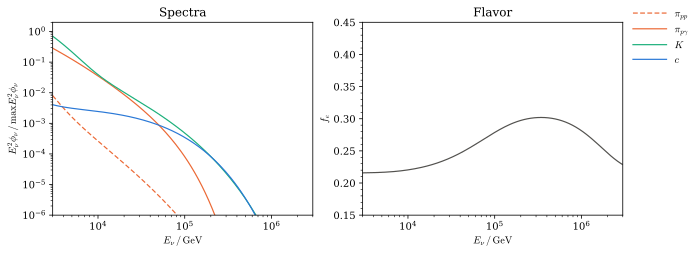

In [32]:
Gj, nj, Bj, ngj, tv = 3.0, 3.6e20, 1.2e9, 2.8e24, 0.1  # lorentz factor, comoving density, field, photon density and variability time
tj = 2 * Gj**2 * c * tv / (Gj * c)  # comoving dynamical time
Tj = hc * (ngj * np.pi**2 / (2 * 1.2020569)) ** (1 / 3) / kB
phj = planck(Tj)
Ej = np.logspace(3, 10, 351)
jet = kit(Ej)

Emax_j = emax(nj, Bj, tj, photomeson(Ep[:, 0], phj)[0])[0]
loss_j, phi_j = photomeson(Ej, phj)
fpp_j = 0.5 * sigma(2 * (Ej * mp + mp**2), "p")[:, None] * 1e-27 * nj * c * tj
Spp_j, Spg_j = split(inject(Ej, Emax_j)[:, None], fpp_j, loss_j * tj, phi_j)
choked = zone(Spp_j, nj, Bj, Spg_j, jet)
Eo = Gj * Ej

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
tot = sum(both(v)[:, 0] for v in choked.values())
top = (Ej**2 * tot).max()
for key, col, ls in [("pi", orange, dash), ("pg", orange, "-"), ("K", aqua, "-"), ("c", blue, "-")]:
    axes[0].plot(Eo, Ej**2 * both(choked[key])[:, 0] / top, color=col, ls=ls)
axes[0].set(xscale="log", yscale="log", xlim=(3e3, 3e6), ylim=(1e-6, 2), title="Spectra", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$")
axes[0].set_ylabel(r"$E_\nu^2 \phi_\nu \,/\, \max E_\nu^2 \phi_\nu$")
axes[1].plot(Eo, earth(choked)[:, 0], color=ink)
axes[1].set(xscale="log", xlim=(3e3, 3e6), ylim=(0.15, 0.45), title="Flavor", xlabel=r"$E_\nu \,/\, \mathrm{GeV}$", ylabel=r"$f_e$")
lines = [Line2D([], [], color=orange, ls=dash), Line2D([], [], color=orange), Line2D([], [], color=aqua), Line2D([], [], color=blue)]
fig.legend(lines, [r"$\pi_{pp}$", r"$\pi_{p\gamma}$", "$K$", "$c$"], loc="outside right upper")
plt.show()

The loss balance gives a comoving maximum energy of $1.6 \times 10^{5} \, \mathrm{GeV}$ which is about a third of the value quoted in that work, and photomeson losses on the thermal X rays exceed proton collisions by one order of magnitude at all relevant energies. The enormous density and field cool pions so strongly that kaons carry most of the neutrino fluence and pions from photomeson interactions follow, while charm catches up with the kaons only above about $2 \times 10^{5} \, \mathrm{GeV}$ in the observer frame where the spectrum already falls steeply. Apart from the magnetar, the choked jet is the only source in this notebook where charm reaches the meson flux at all, although the proton cutoff keeps it from dominating clearly.

## Extension Summary

- **Synchrotron**: Strong fields remove pions and muons above energies set by their mass and lifetime while charm stays untouched, which lowers the charm takeover energy and drives the flavor composition from the full pion chain through the muon damped value towards the charm value.
- **Acceleration**: In dense targets proton collisions cap the maximum energy far below the energies where charm matters, so a charm signal requires acceleration in thinner regions.
- **Disk**: A resolved thin disk brackets the density of the thesis, but protons from above interact in thin upper layers where mesons barely cool, so the charm advantage of the homogeneous slab disappears and thermal disk photons change little.
- **Corona**: Photomeson interactions dominate the corona and turn it into a muon damped pion source without a visible charm component.
- **Magnetar**: Trapped radiation adds photomeson losses that halve the charm peak and add a pion bump one decade below, while charm still dominates at the highest energies.
- **Transients**: The tidal disruption wind is a pure photomeson pion source, and the choked jet cools pions so strongly that kaons lead and charm only catches up near the proton cutoff.

## Extension References

- [Armitage 2022](https://arxiv.org/abs/2201.07262)
- [Enberg 2009](https://doi.org/10.1103/PhysRevD.79.053006)
- [Esteban 2024](https://doi.org/10.1007/JHEP12%282024%29216)
- [Kashti 2005](https://doi.org/10.1103/PhysRevLett.95.181101)
- [Lipari 2007](https://doi.org/10.1103/PhysRevD.75.123005)
- [Mészáros 2001](https://doi.org/10.1103/PhysRevLett.87.171102)
- [Mücke 1999](https://doi.org/10.1071/AS99160)
- [Murase 2020](https://doi.org/10.1103/PhysRevLett.125.011101)
- [Phinney 1989](https://doi.org/10.1017/S0074180900187054)
- [Rees 1988](https://doi.org/10.1038/333523a0)
- [Shakura 1973](https://ui.adsabs.harvard.edu/abs/1973A&A....24..337S)